# Семинар 10. От Transformer к PEFT и SFT

## Часть A. Архитектура Transformer и базовый training pipeline

# `1. Введение`

## `1.1 Постановка задачи машинного перевода`
Давайте для начала разберем seq-to-seq задачу машинного перевода (Machine Translation). Ко всем подобным задачам есть общий подход.

Пусть у нас имеется предложение на исходном языке:
$$
\textbf{x}_{sourse} = x_{i}, i \in [1, n], x_{i} \in V_{sourse}
$$
Предложение на целевом языке:
$$
\textbf{y}_{target} = y_{i}, i \in [1, m], x_{i} \in V_{target}
$$
Параллельный корпус текстов $\textbf{C}$ из пар $(\textbf{x}, \textbf{y})$.
Строго говоря, решается задача максимизации лог-правдоподобия с параметрами $\theta$:
$$
L_{theta} = \sum_{\textbf{x},\textbf{y} \in \textbf{C}} \log p(\textbf{y}|\textbf{x};\theta) \rightarrow \max_{\theta}
$$
Предсказываем последовательно каждый целевой токен перевода в
зависимости от предыдущих (авторегрессионная модель):
$$
p(\textbf{y}|\textbf{x};\theta) = \prod_{j=1}^{m} p(\textbf{y}_{j}|\textbf{y}_{<j},\textbf{x};\theta)
$$
Для задачи перевода существуют и другие подходы, помимо авторегрессионного [cite](https://arxiv.org/pdf/2204.09269.pdf), однако, он является самым популярным.

Базовые архитектуры для решения seq-to-seq задач использует схему кодировщик-декодировщик. В качестве энкодера и декодера обычно берут рекуррентную сеть типа LSTM или GRU:
![Seq-to-Seq](https://sun9-25.userapi.com/impg/lAfWXLvO7bHTSRrLlPJnQz4t8g3g8a9wxNbIig/6otSRhUyqdI.jpg?size=2014x658&quality=96&sign=7fae89512fa58b6f16e55a5fffb4b876&type=album)
Мотивация использования именно таких архитектур заключается в том, что мы не знаем, какой длины у нас будет вход и выход. Более того, их длины обычно отличаются друг от друга.

Узким местом такой архитектуры является вектор $h$, поскольку:
-  Мы хотим уместить весь смысл текста в вектор низкой размерности.
- Вектор $h$ гораздо сильнее зависит от последних слов, нежели от первых.

К тому же, качество такой модели очень сильно падает, если мы пытаемся отправлять в неё последовательности длиннее, чем те, что были в трейне. Необходимо также упомянуть проблему выравнивания (alignment) при обучении языковых моделей. Она заключается в том, что при переводе или генерации текста необходимо учитывать соответствие между словами исходного и целевого языков. Так как слова в разных языках могут иметь различную длину и порядок, то необходимо найти соответствие между ними. Эта проблема становится особенно актуальной при переводе сложных фраз или предложений, когда необходимо учитывать контекст и смысл слов.

## `1.2 Attention is all you need`
Исправить проблемы, описанные выше, помог механизм внимания [cite](https://arxiv.org/pdf/1409.0473.pdf).

Механизм attention в нейронных сетях позволяет модели сосредоточиться на наиболее важных частях входных данных, игнорируя несущественные. Это позволяет сети лучше понимать контекст и улучшать качество предсказаний. Так, в задаче машинного перевода механизм attention позволяет сети решить проблему выравнивания (alignment) и сфокусироваться на ключевых словах и фразах в исходном тексте, что приводит к более точному переводу.

Очень хорошо attention описывает этот слайд из лекции [cite](https://www.youtube.com/watch?v=KhMweP00S44):


<!-- Строго, механизм можно описать так:
- Пусть $a(h, h')$ - функция сходства состояний входа $h$ и выхода $h'$.
- $\alpha_{ti}$ – важность входа $i$ для выхода $t$ (attention score), $\sum_{i}\alpha_{ti} = 1$
- $c_{i}$ – вектор входного контекста для выхода $t$ (context vector) -->

<div>
<img src="https://sun9-37.userapi.com/impg/3gXx6Hi0ylW2VpWyX8Ahp1UlHdUTyBpl0JYlQQ/L9PTei0xScU.jpg?size=1952x1126&quality=96&sign=f46c91e25deb4d3f3d330c0044067e7b&type=album" width="700"/>
</div>

Введем обозначения:
- Вектор выходной последовательности $h'_{t-1}$, по которому мы хотим предсказать следующий вектор назовем запросом (**query**).
- Вектора входной последовательности $h_{i}$ назовем ключами (**keys**)
- Они же и будут являеться значениями (**values**), по которым мы возьмем взвешенную сумму $c_t$.

### Линейные преобразования векторов
Чтобы сделать механизм attention обучаемым и более гибким, можно ввести проекционные матрицы для query, key, value.

### Scaled Dot-Product Attention

Рассмотрим механизм "Scaled Dot-Product Attention", который понадобится нам в дальнейшем в трансформере. На вход подаются **запросы** и **ключи** размерности $d_k$ и **значения** размерности $d_v$. Далее считается скалярное произведение запроса со всеми ключами, каждый результат делится на $\sqrt{d_k}$ и далее применяется softmax, чтобы получить веса для **значений**.

<center><div>
<img src="https://sun9-43.userapi.com/impg/_4nneD33lDOOmUM9nsOjWTnwTPgnmg6pVORdbg/ARWXc-to5LQ.jpg?size=756x1304&quality=96&sign=520a1f13854527903c860231d08ba081&type=album" width="200"/>
</div></center>


<!-- In practice, we compute the attention function on a set of queries
simultaneously, packed together into a matrix $Q$.  The keys and
values are also packed together into matrices $K$ and $V$.  We
compute the matrix of outputs as: -->

На практике, Attention считается для всех **запросов** одновременно – они запаковываются в матрицу $Q$. **Ключи** и **значения** также запакованы в матрицы $K$ и $V$ соответсвенно. Выходная матрица считается следующим образом:

$$
   \mathrm{Attention}(Q, K, V) = \mathrm{softmax}(\frac{QK^T}{\sqrt{d_k}})V
$$

Деление на $\sqrt{d_k}$ нужно чтобы уменьшить дисперсию скалярного произведение и избежать больших чисел под экспонентой.

Реализуем этот механизм:

## `1.4 Импорты`

In [ ]:
# Единый setup для всего ноутбука
import os
import gc
import sys
import math
import copy
import time
import warnings
import importlib
import subprocess
import importlib.metadata as md
from dataclasses import dataclass
from os.path import exists
from typing import Union, Any

HF_STACK = {
    "transformers": "5.3.0",
    "peft": "0.18.1",
    "trl": "0.29.1",
    "datasets": "4.8.4",
    "accelerate": "1.13.0",
    "huggingface_hub": "1.7.2",
    "altair": "6.0.0",
}


def installed_version(package_name: str) -> str | None:
    try:
        return md.version(package_name)
    except md.PackageNotFoundError:
        return None


def pip_install(specs: list[str], *, check: bool = True) -> None:
    if not specs:
        return
    cmd = [sys.executable, "-m", "pip", "install", "-qU", *specs]
    subprocess.run(cmd, check=check)


def ensure_packages(packages: dict[str, str], *, optional: bool = False) -> None:
    missing_or_outdated = [
        f"{name}=={version}"
        for name, version in packages.items()
        if installed_version(name) != version
    ]
    pip_install(missing_or_outdated, check=not optional)


ensure_packages(HF_STACK)

# В text-only ноутбуках broken torchvision иногда ломает импорт transformers/peft.
# Если torchvision установлен некорректно, удаляем его и продолжаем без vision-зависимостей.
def repair_broken_torchvision() -> None:
    if installed_version("torchvision") is None:
        return
    try:
        import torchvision  # noqa: F401
    except Exception as err:
        print(f"Broken torchvision detected and removed: {err}")
        subprocess.run(
            [sys.executable, "-m", "pip", "uninstall", "-y", "torchvision"],
            check=False,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )
        for module_name in list(sys.modules):
            if module_name == "torchvision" or module_name.startswith("torchvision."):
                sys.modules.pop(module_name, None)


repair_broken_torchvision()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except Exception:
    sns = None

import altair as alt

import torch

# bitsandbytes нужен только для QLoRA-блока и ставится опционально.
if torch.cuda.is_available() and installed_version("bitsandbytes") != "0.49.2":
    pip_install(["bitsandbytes==0.49.2"], check=False)

import torch.nn as nn
import torch.nn.functional as F
from torch.nn.functional import log_softmax, pad
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader
from torch.utils.data.distributed import DistributedSampler
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP

try:
    import GPUtil
except Exception:
    GPUtil = None

import tqdm.auto as tqdm

from transformers import (
    AutoModel,
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
    BitsAndBytesConfig,
    pipeline,
)
from peft import (
    LoraConfig,
    AdaLoraConfig,
    PrefixTuningConfig,
    PromptTuningConfig,
    PromptTuningInit,
    PeftModel,
    TaskType,
    get_peft_model,
    prepare_model_for_kbit_training,
)
from datasets import load_dataset, DatasetDict
from trl import SFTConfig, SFTTrainer

warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RUN_EXAMPLES = True
SFT_DEMO_MAX_STEPS = 10
PEFT_DEMO_MAX_STEPS = 10
DATASET_NUM_PROC = max(1, min(4, os.cpu_count() or 1))

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
    else "cpu"
)

BASE_MODEL_ID = "HuggingFaceTB/SmolLM2-135M"
INSTRUCT_MODEL_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"


def ensure_padding_token(tokenizer, model=None):
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    if model is not None:
        model.config.pad_token_id = tokenizer.pad_token_id
        if getattr(model, "generation_config", None) is not None:
            model.generation_config.pad_token_id = tokenizer.pad_token_id
    return tokenizer, model


def load_causal_lm_and_tokenizer(
    model_id: str,
    *,
    device: str | None = None,
    quantization_config=None,
):
    device = device or DEVICE
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    model_kwargs = {}
    if quantization_config is not None:
        model_kwargs["quantization_config"] = quantization_config

    if device == "cuda":
        model_kwargs["device_map"] = "auto"
        model_kwargs["torch_dtype"] = (
            torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        )

    model = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)

    if "device_map" not in model_kwargs:
        model = model.to(device)

    tokenizer, model = ensure_padding_token(tokenizer, model)
    return tokenizer, model


def clear_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def make_text_generation_pipeline(model, tokenizer=None, **kwargs):
    pipe_kwargs = {
        "task": "text-generation",
        "model": model,
        "tokenizer": tokenizer if tokenizer is not None else (model if isinstance(model, str) else None),
    }
    pipe_kwargs.update({k: v for k, v in kwargs.items() if v is not None})
    if torch.cuda.is_available() and isinstance(model, str):
        pipe_kwargs.setdefault("device_map", "auto")
    return pipeline(**pipe_kwargs)


def extract_generated_text(outputs):
    generated = outputs[0]["generated_text"]
    if isinstance(generated, list):
        last_message = generated[-1]
        if isinstance(last_message, dict) and "content" in last_message:
            return last_message["content"]
    return generated


def generate_with_model(
    model,
    tokenizer,
    prompt_or_messages,
    *,
    max_new_tokens: int = 128,
    do_sample: bool = True,
    return_full_text: bool = False,
    **generation_kwargs,
) -> str:
    if isinstance(prompt_or_messages, list):
        prompt_text = tokenizer.apply_chat_template(
            prompt_or_messages,
            tokenize=False,
            add_generation_prompt=True,
        )
    else:
        prompt_text = prompt_or_messages

    inputs = tokenizer(prompt_text, return_tensors="pt")

    try:
        model_device = model.device
    except Exception:
        model_device = next(model.parameters()).device

    inputs = {k: v.to(model_device) for k, v in inputs.items()}
    clean_generation_kwargs = {k: v for k, v in generation_kwargs.items() if v is not None}

    was_training = model.training
    model.eval()
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            **clean_generation_kwargs,
        )
    if was_training:
        model.train()

    if return_full_text:
        tokens = outputs[0]
    else:
        tokens = outputs[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(tokens, skip_special_tokens=True)


def has_bitsandbytes() -> bool:
    return importlib.util.find_spec("bitsandbytes") is not None

In [ ]:
# Some convenience helper functions used throughout the notebook


def is_interactive_notebook():
    return __name__ == "__main__"


def show_example(fn, args=None):
    args = [] if args is None else args
    if __name__ == "__main__" and RUN_EXAMPLES:
        return fn(*args)


def execute_example(fn, args=None):
    args = [] if args is None else args
    if __name__ == "__main__" and RUN_EXAMPLES:
        return fn(*args)
        # fn(*args)


class DummyOptimizer(torch.optim.Optimizer):
    def __init__(self):
        self.param_groups = [{"lr": 0}]
        None

    def step(self):
        None

    def zero_grad(self, set_to_none=False):
        None


class DummyScheduler:
    def step(self):
        None

# `2. Трансформер`

В 2017 году эта архитектура произвела настоящую революцию в задаче машинного перевода обойдя по качеству все имеющиеся на тот момент модели. С тех пор семейство трансформеров невероятно разрослось и эту архитектуру можно встретить в решениях любых задач с текстом.

Архитектура transformer стала прорывом в NLP благодаря своей способности эффективно моделировать длинные зависимости в тексте. Ранее использовавшиеся рекуррентные нейронные сети имели ограничения в обработке длинных последовательностей, что приводило к потере информации и снижению качества моделей.


Transformer же использует механизм **attention**, который позволяет модели сфокусироваться на ключевых словах и фразах, не теряя контекст и смысл текста. Кроме того, transformer использует **параллельную** **обработку** **последовательностей**, что значительно ускоряет обучение моделей и позволяет работать с большими объемами данных. Все это делает transformer одной из самых эффективных архитектур для задач NLP, таких как машинный перевод, генерация текста и анализ тональности.

Трансформеры также стали применять и для других задач, например для картинок и обработки звука.

# `3. Архитектура модели`


Большинство современных моделей преобразования последовательностей (seq-to-seq) имеют структуру Encoder-Decoder.
[(cite)](https://arxiv.org/abs/1409.0473). Энкодер кодирует последовательность $(x_1, ..., x_n)$ в последовательность $\mathbf{z} = (z_1, ...,z_n)$. Получая на вход $\mathbf{z}$, декодер генерирует
последовательность $(y_1,...,y_m)$ поэлементно. На каждом шаге мы имеем авто-регрессионную модель
[(cite)](https://arxiv.org/abs/1308.0850), которая использует уже сгенерированные токены для дальнейшей генерации.

In [ ]:
class EncoderDecoder(nn.Module):
    """
    Стандартная архитектура Encoder-Decoder.
    Базовая модель для Transformer и многих других архитектур seq2seq.
    """

    def __init__(self, encoder, decoder, src_embed, tgt_embed, generator):
        """
        Инициализация слоев модели.

        Аргументы:
            encoder: Модуль кодировщика (обрабатывает входную последовательность).
            decoder: Модуль декодировщика (генерирует выходную последовательность).
            src_embed: Эмбеддинг для исходного текста (source tokens -> vectors).
            tgt_embed: Эмбеддинг для целевого текста (target tokens -> vectors).
            generator: Финальный линейный слой + Softmax для генерации вероятностей слов.
        """
        super(EncoderDecoder, self).__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_embed = src_embed
        self.tgt_embed = tgt_embed
        self.generator = generator

    def forward(self, src, tgt, src_mask, tgt_mask):
        """
        Полный прямой проход (forward pass) модели.
        Принимает маскированные исходную и целевую последовательности и обрабатывает их.

        Аргументы:
            src: Индексы токенов исходного текста [batch_size, src_len].
            tgt: Индексы токенов целевого текста [batch_size, tgt_len].
            src_mask: Маска для скрытия паддингов в исходном тексте.
            tgt_mask: Маска для скрытия паддингов и будущих токенов (causal mask) в целевом тексте.
        """
        # 1. Кодируем исходный текст: encode(src, src_mask) -> получаем memory
        # 2. Декодируем целевой текст: decode(memory, ..., tgt, tgt_mask) -> получаем скрытые состояния
        return self.decode(self.encode(src, src_mask), src_mask, tgt, tgt_mask)

    def encode(self, src, src_mask):
        """
        Процесс кодирования (энкодинг).
        Преобразует токены в эмбеддинги и пропускает их через слои кодировщика.

        Возвращает:
            memory: Контекстные векторы (выход энкодера) [batch_size, src_len, d_model].
        """
        # Переводим токены в векторы и передаем в энкодер вместе с маской
        return self.encoder(self.src_embed(src), src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        """
        Процесс декодирования (декодинг).
        Преобразует целевые токены в эмбеддинги и генерирует новые состояния,
        используя «память» (memory) от кодировщика.

        Возвращает:
            Выходные тензоры декодера перед генерацией токенов [batch_size, tgt_len, d_model].
        """
        # Переводим токены цели в векторы и передаем в декодер
        # вместе с контекстом (memory) от энкодера и масками
        return self.decoder(self.tgt_embed(tgt), memory, src_mask, tgt_mask)


In [ ]:
class Generator(nn.Module):
    """
    Класс генератора (выходного слоя).
    Выполняет стандартный шаг генерации: проецирует скрытые состояния модели
    в размерность словаря и вычисляет логарифм вероятностей для каждого токена.
    """

    def __init__(self, d_model, vocab):
        """
        Инициализация слоя генератора.

        Аргументы:
            d_model: Размерность скрытых состояний модели (скрытый размер вектора).
            vocab: Размер словаря (общее количество уникальных токенов).
        """
        super(Generator, self).__init__()
        # Полносвязный (линейный) слой, который переводит вектор размерности d_model
        # в вектор размерности vocab (размер словаря)
        self.proj = nn.Linear(d_model, vocab)

    def forward(self, x):
        """
        Прямой проход слоя генерации.

        Аргументы:
            x: Выходной тензор из декодера с размерностью [batch_size, tgt_len, d_model].

        Возвращает:
            Логарифмы вероятностей для каждого слова в словаре.
            Размерность: [batch_size, tgt_len, vocab].
        """
        # 1. self.proj(x) считает «логиты» (сырые оценки) для каждого слова в словаре.
        # 2. log_softmax превращает логиты в логарифмы вероятностей по последней оси (dim=-1).
        # Примечание: в современной практике PyTorch часто используют F.log_softmax(..., dim=-1)
        return log_softmax(self.proj(x), dim=-1)

Transformer следует этой общей архитектуре, используя многослойное внутреннее внимание и поэлементные полносвязные слои как для кодировщика, так и для декодировщика. Энкодер показан на левой части рисунка, а декодер на правой.

<div>
<img src="https://sun9-51.userapi.com/impg/pZwJ8Aebk2xdMKOFduF0oliDAjHWFNno52HQoA/KbE1mQmJ5iU.jpg?size=1466x2160&quality=96&sign=b33c1c37906719faac48828ce8aaeaca&type=album", width="400">
</div>

Блок энкодера состоит из двух подблоков (Sublayers). Первый подблок представляет из себя MHSA, а второй – полносвязную NN. После каждого подблока мы прокидываем связи и делаем нормализацию.

Блок декодера состоит уже из трех подблоков. Первый подблок представляет из себя Masked MHSA. Макскирование нужно для исключения утечки таргета. Второй подблок представляет из себя Crossed MHA, "crossed", поскольку декодер смотрит на все выходы последнего блока энкодера. Третий подблок аналогичен второму в энкодере. После каждого подблока мы также прокидываем связи и делаем нормализацию.

## `3.1 Encoder and Decoder Stacks`

### Encoder

Согласно статье, энкодер представляет из себя последовательность $N=6$ одинаковых блоков.

In [ ]:
def clones(module, N):
    "Produce N identical layers."
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])

In [ ]:
class Encoder(nn.Module):
    """
    Основной модуль кодировщика (Encoder).
    Представляет собой последовательный стек (stack) из N одинаковых слоев кодирования.
    """

    def __init__(self, layer, N):
        """
        Инициализация кодировщика.

        Аргументы:
            layer: Базовый слой кодировщика (EncoderLayer), который будет размножен.
            N: Количество слоев в стеке (глубина кодировщика).
        """
        super(Encoder, self).__init__()
        # Создаем N глубоких копий переданного слоя с помощью функции clones.
        # Это позволяет каждому слою в стеке иметь свои собственные обучаемые веса.
        self.layers = clones(layer, N)
        # Финальная нормализация слоев (Layer Normalization) на выходе из всего кодировщика.
        # layer.size — это размерность скрытого состояния (обычно d_model).
        self.norm = LayerNorm(layer.size)

    def forward(self, x, mask):
        """
        Прямой проход кодировщика.
        Поочередно пропускает входной тензор и маску через каждый слой стека.

        Аргументы:
            x: Входной тензор (эмбеддинги токенов) размерности [batch_size, src_len, d_model].
            mask: Маска исходной последовательности для скрытия паддингов [batch_size, 1, src_len].

        Возвращает:
            Нормализованные контекстные векторы (memory) размерности [batch_size, src_len, d_model].
        """
        # Последовательно обновляем тензор x, пропуская его через каждый слой в стеке layers
        for layer in self.layers:
            x = layer(x, mask)
        # Применяем финальную нормализацию перед отправкой результата в декодер
        return self.norm(x)




Не забываем о прокидывании связей [(cite)](https://arxiv.org/abs/1512.03385) для каждого из двух подслоев и дальнейшей нормализации [(cite)](https://arxiv.org/abs/1607.06450).

In [ ]:
class LayerNorm(nn.Module):
    """
    Модуль нормализации слоев (Layer Normalization).
    Стандартизирует активации нейросети по последней размерности (фичам) для ускорения
    и стабилизации процесса обучения.
    """

    def __init__(self, features, eps=1e-6):
        """
        Инициализация параметров нормализации.

        Аргументы:
            features: Размерность признаков (обычно равна d_model).
            eps: Минимальное число (epsilon) для предотвращения деления на ноль.
        """
        super(LayerNorm, self).__init__()
        # Обучаемый параметр масштабирования (гамма, γ). Инициализируется единицами.
        # Обернут в nn.Parameter, чтобы PyTorch обновлял его во время градиентного спуска.
        self.a_2 = nn.Parameter(torch.ones(features))

        # Обучаемый параметр сдвига (бета, β). Инициализируется нулями.
        self.b_2 = nn.Parameter(torch.zeros(features))

        # Константа числовой стабильности
        self.eps = eps

    def forward(self, x):
        """
        Прямой проход слоя нормализации.

        Аргументы:
            x: Входной тензор, обычно размерности [batch_size, seq_len, d_model].

        Возвращает:
            Нормализованный и масштабированный тензор той же размерности.
        """
        # Находим среднее значение (mean) по последней оси (dim=-1).
        # keepdim=True сохраняет размерность оси, превращая ее в 1 для корректного вычитания.
        mean = x.mean(-1, keepdim=True)

        # Находим стандартное отклонение (std) по последней оси.
        std = x.std(-1, keepdim=True)

        # Формула нормализации: (x - mean) / (std + eps)
        # Затем результат умножается на веса масштабирования (a_2) и сдвигается на bias (b_2).
        return self.a_2 * (x - mean) / (std + self.eps) + self.b_2



Таким образом, выход каждого подблока это $\mathrm{LayerNorm}(x +
\mathrm{Sublayer}(x))$. Также перед прокидыванием связи к выходу $\mathrm{Sublayer}(x)$ применяется дропаут.

Чтобы работало прокидывание связи, все подблоки в модели, а также эмбеддинг-слои выдают векторы фиксированной размерности $d_{\text{model}}=512$.

In [ ]:
class SublayerConnection(nn.Module):
    """
    A residual connection followed by a layer norm.
    Note for code simplicity the norm is first as opposed to last.
    """

    def __init__(self, size, dropout):
        super(SublayerConnection, self).__init__()
        self.norm = LayerNorm(size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        "Apply residual connection to any sublayer with the same size."
        return x + self.dropout(sublayer(self.norm(x)))

> Небольшое пояснение к коду выше: можно заметить, что LayerNorm идет перед основным преобразованием подблока, а не после него, как в изначальной статье. Оказывается, так более правильно, побробности тут: [cite](https://arxiv.org/pdf/2002.04745.pdf)

Как уже было сказано, каждый блок энкодера разбит на два подблока – MHSA и FCN.

In [ ]:
class EncoderLayer(nn.Module):
    """
    Одиночный слой кодировщика (Encoder Layer).
    Состоит из двух основных подслоев:
    1. Механизм самовнимания (Multi-Head Self-Attention).
    2. Полносвязная сеть прямого распространения (Position-wise Feed-Forward Network).
    Оба подслоя обернуты в остаточные связи с нормализацией (SublayerConnection).
    """

    def __init__(self, size, self_attn, feed_forward, dropout):
        """
        Инициализация слоя кодировщика.

        Аргументы:
            size: Размерность скрытого состояния (d_model).
            self_attn: Инициализированный модуль многоголового внимания (MultiHeadedAttention).
            feed_forward: Инициализированный модуль полносвязной сети (PositionwiseFeedForward).
            dropout: Коэффициент дропаута для остаточных связей.
        """
        super(EncoderLayer, self).__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward

        # Создаем массив из 2 независимых копий модуля SublayerConnection.
        # Каждый из них отвечает за свою остаточную связь (Residual Connection) + LayerNorm:
        # self.sublayer[0] — управляет входом и выходом блока самовнимания.
        # self.sublayer[1] — управляет входом и выходом блока Feed-Forward сети.
        self.sublayer = clones(SublayerConnection(size, dropout), 2)
        self.size = size

    def forward(self, x, mask):
        """
        Прямой проход слоя кодировщика.
        Повторяет структуру левой части оригинальной схемы Transformer (Figure 1).

        Аргументы:
            x: Входной тензор слоя [batch_size, src_len, d_model].
            mask: Маска для скрытия паддингов [batch_size, 1, src_len].
        """

        # =========================================================================
        # ПОДСЛОЙ 1: МНОГОГОЛОВОЕ САМОВНИМАНИЕ (MULTI-HEAD SELF-ATTENTION)
        # =========================================================================
        # Метод SublayerConnection.forward(x, sublayer) ожидает на вход:
        #   1. Тензор `x`
        #   2. Вызываемый объект (функцию), принимающий ровно ОДИН аргумент: `sublayer(x)`
        #
        # Но метод self.self_attn(query, key, value, mask) требует ЧЕТЫРЕ аргумента.
        # Чтобы совместить их, мы используем анонимную лямбда-функцию `lambda x: ...`.
        # Она принимает нормализованный внутри SublayerConnection тензор `x` и дублирует
        # его в качестве Query, Key и Value (поэтому оно и называется САМОВНИМАНИЕМ).
        # Маска (`mask`) пробрасывается без изменений, чтобы занулить веса паддингов.
        #
        # Внутри self.sublayer[0] происходит следующая цепочка:
        # x_norm = LayerNorm(x)
        # attn_out = self.self_attn(query=x_norm, key=x_norm, value=x_norm, mask=mask)
        # x = x + Dropout(attn_out)
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask))

        # =========================================================================
        # ПОДСЛОЙ 2: СЕТЬ ПРЯМОГО РАСПРОСТРАНЕНИЯ (POSITION-WISE FEED-FORWARD)
        # =========================================================================
        # Полученный на предыдущем шаге тензор `x` передается во вторую остаточную связь.
        #
        # Модуль self.feed_forward по умолчанию принимает ровно один аргумент `x`
        # (внутреннее состояние текущего токена), поэтому здесь нам не нужна лямбда-функция.
        # Мы можем передать метод `self.feed_forward` напрямую как объект.
        #
        # Внутри self.sublayer[1] происходит следующая цепочка:
        # x_norm = LayerNorm(x)
        # ff_out = self.feed_forward(x_norm)
        # x = x + Dropout(ff_out)
        #
        # Результат возвращается как выход текущего слоя кодировщика.
        return self.sublayer[1](x, self.feed_forward)


### Decoder

Декодер также представляет из себя последовательность из $N=6$ идентичных блоков.

In [ ]:
class Decoder(nn.Module):
    """
    Основной модуль декодировщика (Decoder).
    Представляет собой последовательный стек (stack) из N одинаковых слоев декодирования.
    Отвечает за пошаговую генерацию целевой последовательности с использованием маскирования.
    """

    def __init__(self, layer, N):
        """
        Инициализация декодировщика.

        Аргументы:
            layer: Базовый слой декодировщика (DecoderLayer), который будет размножен.
            N: Количество слоев в стеке (глубина декодировщика).
        """
        super(Decoder, self).__init__()
        # Создаем N независимых глубоких копий переданного слоя DecoderLayer.
        # Каждый слой в процессе обучения настраивает свои уникальные веса.
        self.layers = clones(layer, N)
        # Финальная нормализация слоев (Layer Normalization) на выходе из всего декодировщика.
        # layer.size — это размерность скрытого состояния (обычно d_model).
        self.norm = LayerNorm(layer.size)

    def forward(self, x, memory, src_mask, tgt_mask):
        """
        Прямой проход декодировщика.
        Последовательно пропускает целевые токены через каждый слой стека,
        подмешивая контекст из кодировщика.

        Аргументы:
            x: Входной тензор (эмбеддинги целевых токенов) размерности [batch_size, tgt_len, d_model].
            memory: Выходные контекстные векторы из кодировщика [batch_size, src_len, d_model].
            src_mask: Маска исходного текста (для игнорирования паддингов в memory) [batch_size, 1, src_len].
            tgt_mask: Маска целевого текста (для игнорирования паддингов и будущих токенов) [batch_size, tgt_len, tgt_len].

        Возвращает:
            Нормализованные скрытые состояния декодера размерности [batch_size, tgt_len, d_model],
            которые затем передаются в слой Generator.
        """
        # Последовательно обновляем тензор x, пропуская его через каждый слой в стеке layers.
        # Каждый слой DecoderLayer принимает текущее состояние x, "память" энкодера и обе маски.
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)

        # Применяем финальную нормализацию к выходу последнего слоя перед генерацией токенов
        return self.norm(x)

В дополнении к двум подблокам, которые есть в энкодере, декодер содержит дополнительный подблок, отвечающий за многомерное внимание на выходы последнего блока энкодера в стеке. Также как и в энкодере, вокруг каждого подблока есть прокидывание связей и нормализация.

In [ ]:
class DecoderLayer(nn.Module):
    """
    Одиночный слой декодировщика (Decoder Layer).
    В отличие от кодировщика, состоит из трех основных подслоев:
    1. Маскированное многоголовое самовнимание (Masked Multi-Head Self-Attention).
    2. Перекрестное внимание (Encoder-Decoder / Source Attention).
    3. Полносвязная сеть прямого распространения (Position-wise Feed-Forward Network).
    Все три подслоя обернуты в остаточные связи с нормализацией (SublayerConnection).
    """

    def __init__(self, size, self_attn, src_attn, feed_forward, dropout):
        """
        Инициализация слоя декодировщика.

        Аргументы:
            size: Размерность скрытого состояния (d_model).
            self_attn: Инициализированный модуль самовнимания для целевого текста.
            src_attn: Инициализированный модуль перекрестного внимания (вход из энкодера).
            feed_forward: Инициализированный модуль полносвязной сети.
            dropout: Коэффициент дропаута для остаточных связей.
        """
        super(DecoderLayer, self).__init__()
        self.size = size
        self.self_attn = self_attn
        self.src_attn = src_attn
        self.feed_forward = feed_forward

        # Создаем массив из 3 независимых копий модуля SublayerConnection.
        # Каждая копия управляет своей остаточной связью (Residual + LayerNorm):
        # self.sublayer[0] — для маскированного самовнимания (Self-Attention).
        # self.sublayer[1] — для перекрестного внимания (Source Attention).
        # self.sublayer[2] — для сети прямого распространения (Feed-Forward).
        self.sublayer = clones(SublayerConnection(size, dropout), 3)

    def forward(self, x, memory, src_mask, tgt_mask):
        """
        Прямой проход слоя декодировщика.
        Повторяет структуру правой части оригинальной схемы Transformer (Figure 1).

        Аргументы:
            x: Текущее состояние целевой последовательности [batch_size, tgt_len, d_model].
            memory: Контекстные векторы (выход энкодера) [batch_size, src_len, d_model].
            src_mask: Маска исходного текста (скрывает паддинги в memory) [batch_size, 1, src_len].
            tgt_mask: Маска целевого текста (скрывает паддинги и будущие токены) [batch_size, tgt_len, tgt_len].
        """
        # Сохраняем ссылку на контекст энкодера в короткую переменную m для удобства
        m = memory

        # =========================================================================
        # ПОДСЛОЙ 1: МАСКИРОВАННОЕ САМОВНИМАНИЕ (SELF-ATTENTION)
        # =========================================================================
        # Декодер смотрит на уже сгенерированные им токены целевой последовательности.
        # Поскольку это самовнимание, Query, Key и Value строятся из одного тензора `x`.
        # Используется `tgt_mask`, которая запрещает модели "подглядывать вперед"
        # на токены, которые она еще не должна была сгенерировать.
        #
        # Внутри self.sublayer[0] происходит: x = x + Dropout(self.self_attn(LN(x), LN(x), LN(x), tgt_mask))
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, tgt_mask))

        # =========================================================================
        # ПОДСЛОЙ 2: ПЕРЕКРЕСТНОЕ ВНИМАНИЕ (SRC-ATTENTION / CROSS-ATTENTION)
        # =========================================================================
        # Этот слой связывает энкодер и декодер.
        # ВАЖНО:
        #   - Query (запрос) формируется из текущего состояния декодера `x`.
        #   - Key (ключ) и Value (значение) берутся из выхода энкодера `m` (memory).
        # Модель ищет соответствия между тем, что генерирует сейчас (x), и тем,
        # что было на входе в кодировщик (m).
        # Используется `src_mask`, чтобы не обращать внимания на паддинги в исходном тексте.
        #
        # Внутри self.sublayer[1] происходит: x = x + Dropout(self.src_attn(LN(x), m, m, src_mask))
        x = self.sublayer[1](x, lambda x: self.src_attn(x, m, m, src_mask))

        # =========================================================================
        # ПОДСЛОЙ 3: СЕТЬ ПРЯМОГО РАСПРОСТРАНЕНИЯ (POSITION-WISE FEED-FORWARD)
        # =========================================================================
        # Финальная обработка полученного объединенного представления.
        # Передаем метод `self.feed_forward` напрямую, так как он принимает один аргумент.
        #
        # Внутри self.sublayer[2] происходит: x = x + Dropout(self.feed_forward(LN(x)))
        return self.sublayer[2](x, self.feed_forward)


Подблок в блоке декодера, отвечающий за самовнимание, изменен по сравнению с аналогичным блоком в энкодере – в него добавлено маскирование. Это нужно для того, чтобы трансформер не заглядывал в "будущее". Также, важным является то, что вход трансформера сдвинут на 1 позицию вправо, чтобы гарантировать, что предсказание на позиции $i$ зависит только от элементов на позициях меньше или равно $i$.

In [ ]:
def subsequent_mask(size):
    "Mask out subsequent positions."
    attn_shape = (1, size, size)
    subsequent_mask = torch.triu(torch.ones(attn_shape), diagonal=1).type(
        torch.uint8
    )
    return subsequent_mask == 0

> Маска внимания, изображенная ниже, показывает, на какие позиции слово выходной последовательности (row) может смотреть (column). Запрещено смотреть на слова, которые идут дальше во время обучения.

In [ ]:
def example_mask():
    LS_data = pd.concat(
        [
            pd.DataFrame(
                {
                    "Subsequent Mask": subsequent_mask(20)[0][x, y].flatten(),
                    "Window": y,
                    "Position": x,
                }
            )
            for y in range(20)
            for x in range(20)
        ]
    )

    return (
        alt.Chart(LS_data)
        .mark_rect()
        .properties(height=250, width=250)
        .encode(
            alt.X("Window:O"),
            alt.Y("Position:O"),
            alt.Color("Subsequent Mask:Q", scale=alt.Scale(scheme="viridis")),
        )
        .interactive()
    )


show_example(example_mask)

alt.Chart(...)

Перейдем теперь к механизму MultiHead Attention.

<center>
<div>
<img src="https://sun9-71.userapi.com/impg/uvkYRjjCN_ZbxfUknN3r8qyK7RNv-ggPrrMDrw/kAwSmQ1etEQ.jpg?size=835x1126&quality=96&sign=9b25627047629c98fbc4a6569a0847b7&type=album", width="400">
</div>
</center>

Многомерное внимание (**MultiHead Attention**, **MHA**) позволяет модели выучивать различные аспекты текста. Например, грамматику, синтаксические связи, связи между разными частями текста. При одномерном Attention все эти закономерности сливаются в одну "голову", что может препятствовать хорошему пониманию текста.

$$
\mathrm{MultiHead}(Q, K, V) =
    \mathrm{Concat}(\mathrm{head_1}, ..., \mathrm{head_h})W^O \\
    \text{where}~\mathrm{head_i} = \mathrm{Attention}(QW^Q_i, KW^K_i, VW^V_i)
$$

Используем проекционные матрицы $W^Q_i \in
\mathbb{R}^{d_{\text{model}} \times d_k}$, $W^K_i \in
\mathbb{R}^{d_{\text{model}} \times d_k}$, $W^V_i \in
\mathbb{R}^{d_{\text{model}} \times d_v}$ and $W^O \in
\mathbb{R}^{hd_v \times d_{\text{model}}}$, которые как раз и являются обучаемыми параметрами.

В оригинальной статье использовалось $h=8$ "голов". Для каждой из них использовались размерности $d_k=d_v=d_{\text{model}}/h=64$. Поскольку мы уменьшили размерность векторов внутри одной "головы", суммарные вычислительные затраты близки к тем, какие мы бы получили с одной головой с полной размерностью $d_{\text{model}}$.

Давайте посмотрим на иллюстрацию механизма MHA в трансформере:
![Механизм attention](https://jalammar.github.io/images/t/transformer_multi-headed_self-attention-recap.png)

In [ ]:

def attention(query, key, value, mask=None, dropout=None):
    """
    Вычисление масштабированного скалярного произведения (Scaled Dot-Product Attention).

    Математическая формула:
    Attention(Q, K, V) = softmax( (Q * K^T) / sqrt(d_k) ) * V

    Аргументы:
        query: Тензор запросов [..., seq_len_q, d_k]
        key: Тензор ключей [..., seq_len_k, d_k]
        value: Тензор значений [..., seq_len_v, d_v] (обычно d_k == d_v)
        mask: Маска для скрытия определенных токенов (паддингов или будущих токенов) [..., seq_len_q, seq_len_k]
        dropout: Опциональный модуль nn.Dropout для регуляризации весов внимания

    Возвращает:
        Выходной тензор взвешенных значений [..., seq_len_q, d_v]
        Тензор весов внимания p_attn (распределение внимания) [..., seq_len_q, seq_len_k]
    """
    # 1. Получаем размерность d_k (размер вектора ключа/запроса) из последней оси тензора query.
    # Она нужна для масштабирования, чтобы избежать слишком больших значений при скалярном умножении.
    d_k = query.size(-1)

    # 2. Перемножаем матрицы Query и Key.
    # key.transpose(-2, -1) меняет местами две последние размерности ключей (транспонирование).
    # Результат (scores) показывает степень близости/релевантности каждого запроса к каждому ключу.
    # Делим на sqrt(d_k), чтобы стабилизировать градиенты (Scaled Dot-Product).
    # Размерность scores: [..., seq_len_q, seq_len_k]
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)

    # 3. Применение маски (если она передана).
    # Заменяем элементы, где mask == 0 (или False), на очень маленькое число (-1e9, минус миллиард).
    # Это делается для того, чтобы после операции Softmax вероятность этих позиций стала строго равна 0,
    # и модель полностью проигнорировала их (например, паддинги или токены из будущего).
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    # 4. Применяем функцию Softmax по последней оси (dim=-1).
    # Превращаем сырые оценки близости (scores) в распределение вероятностей (веса внимания).
    # Сумма весов для каждого токена запроса будет равна 1.
    # Размерность p_attn: [..., seq_len_q, seq_len_k]
    p_attn = scores.softmax(dim=-1)

    # 5. Применяем дропаут к весам внимания (если он передан) для борьбы с переобучением.
    # Случайным образом зануляет некоторые веса внимания во время обучения.
    if dropout is not None:
        p_attn = dropout(p_attn)

    # 6. Умножаем полученную матрицу весов внимания p_attn на матрицу значений Value.
    # В результате токены с бóльшим весом внимания внесут бóльший вклад в финальный вектор.
    # Возвращаем: (результат внимания, саму матрицу весов для возможности её визуализации).
    return torch.matmul(p_attn, value), p_attn


In [ ]:
class MultiHeadedAttention(nn.Module):
    """
    Модуль многоголового внимания (Multi-Head Attention).
    Позволяет модели одновременно прорабатывать информацию из разных подпространств
    представлений в разных позициях (Figure 2 в оригинальной статье).
    """

    def __init__(self, h, d_model, dropout=0.1):
        """
        Инициализация параметров многоголового внимания.

        Аргументы:
            h: Количество голов внимания (heads).
            d_model: Общая размерность модели (скрытый размер вектора).
            dropout: Коэффициент дропаута для весов внимания.
        """
        super(MultiHeadedAttention, self).__init__()
        # Проверяем, что общая размерность делится нацело на количество голов
        assert d_model % h == 0

        # d_k — размерность вектора для одной головы (проекция в подпространство).
        # Мы предполагаем, что размерность ключей/запросов (d_k) равна размерности значений (d_v).
        self.d_k = d_model // h
        self.h = h

        # Создаем 4 линейных слоя (nn.Linear) с помощью функции clones:
        # Первые три (0, 1, 2) — для линейной проекции Query, Key и Value соответственно.
        # Четвертый (3-й с индексом -1) — для финального объединения голов (Output projection).
        self.linears = clones(nn.Linear(d_model, d_model), 4)

        # Сюда будет временно сохраняться матрица весов внимания (для визуализации)
        self.attn = None
        # Модуль дропаута, который будет передан в функцию attention
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, query, key, value, mask=None):
        """
        Прямой проход механизма многоголового внимания.
        Реализует схему "Figure 2" из оригинальной статьи.

        Аргументы:
            query: Тензор запросов [batch_size, seq_len_q, d_model]
            key: Тензор ключей [batch_size, seq_len_k, d_model]
            value: Тензор значений [batch_size, seq_len_v, d_model]
            mask: Маска для скрытия токенов [batch_size, 1, seq_len_k] (или аналогичная)
        """
        if mask is not None:
            # Добавляем ось для голов (индекс 1), чтобы маска автоматически дублировалась (broadcasting)
            # на все h голов. Было: [batch_size, 1, seq_len_k] -> Стало: [batch_size, 1, 1, seq_len_k]
            mask = mask.unsqueeze(1)

        nbatches = query.size(0) # Размер батча (batch_size)

        # ---------------------------------------------------------------------
        # 1) ПРОЕКЦИЯ И РАЗДЕЛЕНИЕ НА ГОЛОВЫ (Linear projections)
        # ---------------------------------------------------------------------
        # В цикле zip сопоставляем линейные слои и тензоры: (lin0->query, lin1->key, lin2->value).
        # Для каждого тензора происходит следующее:
        #   а) lin(x) — Проецируем из d_model в d_model: [batch_size, seq_len, d_model]
        #   б) view(...) — Разделяем d_model на головы (h) и их размерность (d_k): [batch_size, seq_len, h, d_k]
        #   в) transpose(1, 2) — Меняем местами оси длины и голов.
        #      Это нужно, чтобы головы шли СРАЗУ после батча, и функция attention могла обрабатывать их параллельно.
        # Итоговая размерность каждого тензора: [batch_size, h, seq_len, d_k]
        query, key, value = [
            lin(x).view(nbatches, -1, self.h, self.d_k).transpose(1, 2)
            for lin, x in zip(self.linears, (query, key, value))
        ]

        # ---------------------------------------------------------------------
        # 2) ВЫЧИСЛЕНИЕ ВНИМАНИЯ (Apply attention)
        # ---------------------------------------------------------------------
        # Вызываем функцию attention (Scaled Dot-Product Attention) для трансформированных батчей.
        # x: результат перемножения весов на Value. Размерность: [batch_size, h, seq_len_q, d_k]
        # self.attn: матрица весов распределения внимания. Размерность: [batch_size, h, seq_len_q, seq_len_k]
        x, self.attn = attention(
            query, key, value, mask=mask, dropout=self.dropout
        )

        # ---------------------------------------------------------------------
        # 3) ОБЪЕДИНЕНИЕ ГОЛОВ (Concatenate) И ФИНАЛЬНАЯ ПРОЕКЦИЯ
        # ---------------------------------------------------------------------
        # Нам нужно склеить результаты всех голов обратно в один вектор размерности d_model.
        #   а) transpose(1, 2) — Возвращаем оси на место: [batch_size, seq_len_q, h, d_k]
        #   б) contiguous() — Пересобираем тензор в памяти последовательно (требуется после transpose для view)
        #   в) view(...) — Схлопываем две последние оси (h * d_k == d_model).
        # Итоговая размерность x: [batch_size, seq_len_q, d_model]
        x = (
            x.transpose(1, 2)
            .contiguous()
            .view(nbatches, -1, self.h * self.d_k)
        )

        # Явно освобождаем память от промежуточных тензоров, так как они больше не нужны
        del query
        del key
        del value

        # Пропускаем объединенный тензор через последний, 4-й линейный слой (self.linears[-1])
        return self.linears[-1](x)


### Как Attention применяется в трансформере

Суммаризуем, как трансформер использует MHA:

<!-- 1) In "encoder-decoder attention" layers, the queries come from the
previous decoder layer, and the memory keys and values come from the
output of the encoder. This allows every position in the decoder to
attend over all positions in the input sequence.  This mimics the
typical encoder-decoder attention mechanisms in sequence-to-sequence
models such as [(cite)](https://arxiv.org/abs/1609.08144). -->
1. В подблоке Encoder-Decoder Attention (MHCA) запросы поступают из предыдущего уровня декодировщика, а ключи и значения поступают из выхода кодировщика – их еще называют памятью (**memory**). Это позволяет каждой позиции в декодере
смотреть на все токены во входной последовательности.


<!-- 2) The encoder contains self-attention layers.  In a self-attention
layer all of the keys, values and queries come from the same place,
in this case, the output of the previous layer in the encoder.  Each
position in the encoder can attend to all positions in the previous
layer of the encoder. -->
2. Кодировщик содержит слои Self-Attention. В этом слое все ключи, значения и запросы поступают из одной и той же последовательности, в данном случае из вывода предыдущего кодировщика. Каждая позиция в кодировщике может "обращать внимание" на все позиции в предыдущем блоке кодировщика.


<!-- 3) Similarly, self-attention layers in the decoder allow each
position in the decoder to attend to all positions in the decoder up
to and including that position.  We need to prevent leftward
information flow in the decoder to preserve the auto-regressive
property.  We implement this inside of scaled dot-product attention
by masking out (setting to $-\infty$) all values in the input of the
softmax which correspond to illegal connections. -->

3. Аналогично, подблоки Self-Attention в декодировщике позволяют каждой позиции смотреть на все позиции в декодере до текущей включительно. Нам нужно предотвратить утечку информации справа-налево в декодере, чтобы сохранить свойство авторегрессии. Это реализуется внутри масштабированного скалярного произведения с помощью маскирования (установив значение $-\infty$) значений на входе softmax, которые соответствуют недопустимым позициям.

## `3.2 Position-wise Feed-Forward Networks`

<!-- In addition to attention sub-layers, each of the layers in our
encoder and decoder contains a fully connected feed-forward network,
which is applied to each position separately and identically.  This
consists of two linear transformations with a ReLU activation in
between. -->
В дополнение к подблокам внимания, каждый из блоков в энкодере и декодере содержит полносвязную сеть, которая применяется к каждой позиции отдельно и идентично. Он состоит из двух линейных преобразований с активацией ReLU между ними.

$$\mathrm{FFN}(x)=\max(0, xW_1 + b_1) W_2 + b_2$$

<!-- While the linear transformations are the same across different
positions, they use different parameters from layer to
layer. Another way of describing this is as two convolutions with
kernel size 1.  The dimensionality of input and output is
$d_{\text{model}}=512$, and the inner-layer has dimensionality
$d_{ff}=2048$. -->
Хотя линейные преобразования одинаковы для разных позиций, они используют разные параметры от блока к блоку. Размерность ввода и вывода равна $d_{\text{model}}=512$, а внутренний слой имеет размерность $d_{ff}=2048$.

In [ ]:
import torch.nn as nn

class PositionwiseFeedForward(nn.Module):
    """
    Полносвязная сеть прямого распространения (Position-wise Feed-Forward Network).

    Применяется к каждому токену (позиции) независимо и одинаково.
    Состоит из двух линейных преобразований с активацией ReLU и дропаутом между ними.

    Математическая формула:
    FFN(x) = max(0, x * W_1 + b_1) * W_2 + b_2
    """

    def __init__(self, d_model, d_ff, dropout=0.1):
        """
        Инициализация слоев полносвязной сети.

        Аргументы:
            d_model: Размерность входного и выходного скрытого состояния (размер модели).
            d_ff: Размерность промежуточного (скрытого) слоя, обычно в 4 раза больше d_model.
            dropout: Коэффициент дропаута для регуляризации.
        """
        super(PositionwiseFeedForward, self).__init__()
        # Первый линейный слой: проецирует данные из пространства d_model в более широкое пространство d_ff
        self.w_1 = nn.Linear(d_model, d_ff)

        # Второй линейный слой: возвращает данные из пространства d_ff обратно в размерность d_model
        self.w_2 = nn.Linear(d_ff, d_model)

        # Слой дропаута для предотвращения переобучения (применяется к промежуточному представлению)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        """
        Прямой проход полносвязной сети.

        Аргументы:
            x: Входной тензор, обычно размерности [batch_size, seq_len, d_model].

        Возвращает:
            Обработанный тензор той же размерности [batch_size, seq_len, d_model].
        """
        # Цепочка преобразований:
        # 1. self.w_1(x) — Применяем первое линейное преобразование.
        # 2. .relu() — Применяем функцию активации (зануляем все отрицательные значения).
        # 3. self.dropout(...) — Применяем дропаут к активированным фичам.
        # 4. self.w_2(...) — Применяем второе линейное преобразование к результату.
        return self.w_2(self.dropout(self.w_1(x).relu()))


## `3.3 Embeddings`

<!-- Similarly to other sequence transduction models, we use learned
embeddings to convert the input tokens and output tokens to vectors
of dimension $d_{\text{model}}$.  We also use the usual learned
linear transformation and softmax function to convert the decoder
output to predicted next-token probabilities.  In our model, we
share the same weight matrix between the two embedding layers and
the pre-softmax linear transformation, similar to
[(cite)](https://arxiv.org/abs/1608.05859). In the embedding layers,
we multiply those weights by $\sqrt{d_{\text{model}}}$. -->

Как и в других моделях seq-to-seq, мы используем обучаемые эмбеддинги для преобразования входных и выходных (целевых) токенов в векторы размерности $d_{\text{model}}$.

In [ ]:
import math
import torch.nn as nn

class Embeddings(nn.Module):
    """
    Модуль эмбеддингов (Embeddings).
    Превращает дискретные индексы слов (токенов) в плотные непрерывные векторы
    заданной размерности d_model.
    """

    def __init__(self, d_model, vocab):
        """
        Инициализация слоя эмбеддингов.

        Аргументы:
            d_model: Размерность выходного вектора для каждого слова (скрытый размер модели).
            vocab: Размер словаря (общее количество уникальных токенов).
        """
        super(Embeddings, self).__init__()

        # Создаем таблицу поиска (Look-Up Table, lut).
        # Это матрица размера [vocab, d_model], где каждая строка хранит
        # обучаемый вектор для конкретного слова из словаря.
        self.lut = nn.Embedding(vocab, d_model)

        # Сохраняем размерность модели для использования при прямом проходе
        self.d_model = d_model

    def forward(self, x):
        """
        Прямой проход слоя эмбеддингов.

        Аргументы:
            x: Тензор с индексами токенов [batch_size, seq_len].

        Возвращает:
            Тензор векторов слов размерности [batch_size, seq_len, d_model].
        """
        # 1. self.lut(x) извлекает вектор для каждого индекса токена.
        # 2. Результат умножается на квадратный корень из d_model (math.sqrt(self.d_model)).
        #
        # ЗАЧЕМ НУЖНО УМНОЖЕНИЕ НА math.sqrt(d_model)?
        #   - При инициализации веса эмбеддингов имеют маленькую дисперсию.
        #     Умножение масштабирует их значения вверх, делая их сравнимыми по величине
        #     с весами позиционного кодирования (Positional Encoding), которые добавляются сразу после этого.
        #   - Без этого масштабирования позиционные сигналы (синусы и косинусы) "заглушили" бы
        #     семантический смысл самих векторов слов, и модель хуже понимала бы значения слов.
        return self.lut(x) * math.sqrt(self.d_model)


## `3.4 Positional Encoding`

<!-- Since our model contains no recurrence and no convolution, in order
for the model to make use of the order of the sequence, we must
inject some information about the relative or absolute position of
the tokens in the sequence.  To this end, we add "positional
encodings" to the input embeddings at the bottoms of the encoder and
decoder stacks.  The positional encodings have the same dimension
$d_{\text{model}}$ as the embeddings, so that the two can be summed.
There are many choices of positional encodings, learned and fixed
[(cite)](https://arxiv.org/pdf/1705.03122.pdf).

In this work, we use sine and cosine functions of different frequencies: -->

Наша модель не содержит рекурсии и сверток, поэтому, чтобы она могла учитывать порядок последовательности, мы должны ввести некоторую информацию об относительном или абсолютном положении токенов в последовательности. С этой целью мы добавляем "позиционные эмбеддинги" к входным представлениям в нижней части стеков кодировщика и декодировщика. Позиционные эмбеддинги имеют ту же размерность $d_{\text{model}}$, что и эмбеддинги токенов, так чтобы их можно было суммировать. Есть много вариантов позиционных кодировок, обучаемых и фиксированных [(cite)](https://arxiv.org/pdf/1705.03122.pdf).

В классическом трансформере используются функции синуса и косинуса разных частот:

$$PE_{(pos,2i)} = \sin(pos / 10000^{2i/d_{\text{model}}})$$

$$PE_{(pos,2i+1)} = \cos(pos / 10000^{2i/d_{\text{model}}})$$

<!-- where $pos$ is the position and $i$ is the dimension.  That is, each
dimension of the positional encoding corresponds to a sinusoid.  The
wavelengths form a geometric progression from $2\pi$ to $10000 \cdot
2\pi$.  We chose this function because we hypothesized it would
allow the model to easily learn to attend by relative positions,
since for any fixed offset $k$, $PE_{pos+k}$ can be represented as a
linear function of $PE_{pos}$. -->
где $pos$ — позиция, а $i$ — размерность. Длины волн образуют геометрическую прогрессию от $2\pi$ до $10000 \cdot
2\pi$. Эта функция выбрана из предположения, что она позволит модели легко научиться следить за относительными позициями, поскольку для любого фиксированного смещения $k$, $PE_{pos+k}$ можно представить как линейную функцию $PE_{pos}$.

<!-- In addition, we apply dropout to the sums of the embeddings and the
positional encodings in both the encoder and decoder stacks.  For
the base model, we use a rate of $P_{drop}=0.1$. -->

Кроме того, тут применяется dropout к суммам входных и позиционных эмбеддингов как в стеках кодировщика, так и в стеках декодировщика. Вс статье использовано значение $P_{drop}=0.1$.


In [ ]:
class PositionalEncoding(nn.Module):
    "Implement the PE function."

    def __init__(self, d_model, dropout, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Compute the positional encodings once in log space.
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * -(math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, : x.size(1)].requires_grad_(False)
        return self.dropout(x)


<!-- > Below the positional encoding will add in a sine wave based on position. The frequency and offset of the wave is different for each dimension. -->

> Ниже мы добавляем позиционные эмбеддинги в зависимости от позиции. Частота и смещение разные для каждой размерности

In [ ]:
def example_positional():
    pe = PositionalEncoding(20, 0)
    y = pe.forward(torch.zeros(1, 100, 20))

    data = pd.concat(
        [
            pd.DataFrame(
                {
                    "embedding": y[0, :, dim],
                    "dimension": dim,
                    "position": list(range(100)),
                }
            )
            for dim in [4, 5, 6, 7]
        ]
    )

    return (
        alt.Chart(data)
        .mark_line()
        .properties(width=800)
        .encode(x="position", y="embedding", color="dimension:N")
        .interactive()
    )


show_example(example_positional)

alt.Chart(...)


<!-- We also experimented with using learned positional embeddings
[(cite)](https://arxiv.org/pdf/1705.03122.pdf) instead, and found
that the two versions produced nearly identical results.  We chose
the sinusoidal version because it may allow the model to extrapolate
to sequence lengths longer than the ones encountered during
training. -->
Также можно использовать обучаемые позиционные эмбеддинги, однако, результаты получаются практически идентичными [(cite)](https://arxiv.org/pdf/1705.03122.pdf).

torch.Size([1, 1000, 512])


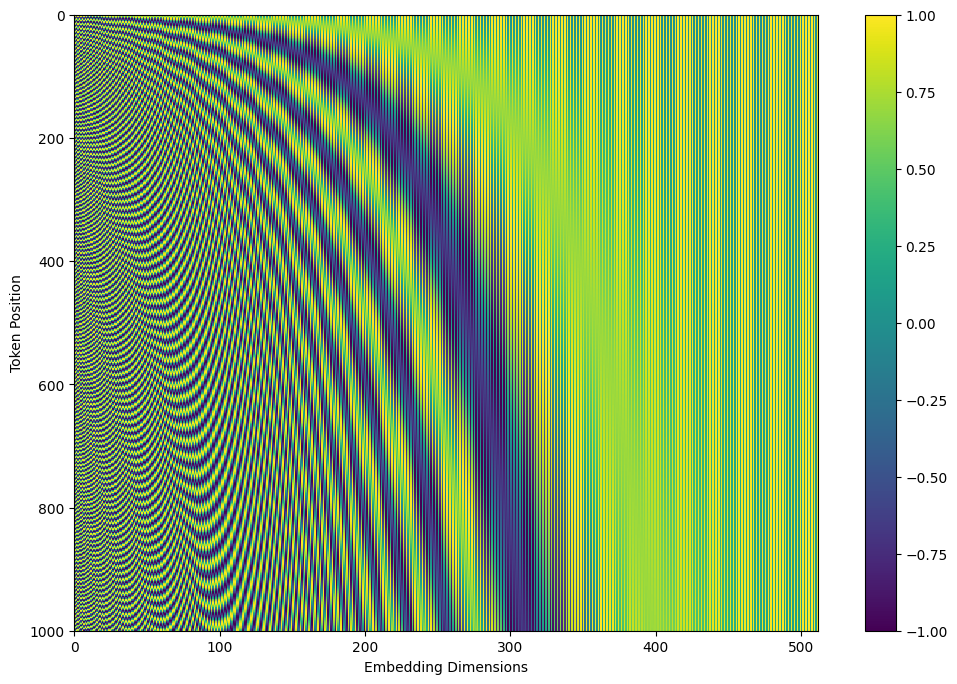

In [ ]:
tokens = 1000
dimensions = 512

pe = PositionalEncoding(dimensions, 0)
pos_encoding = pe.forward(torch.zeros(1, tokens, dimensions))

pos_encodings = pos_encoding.reshape([1, tokens, dimensions]).numpy()
print(pos_encoding.shape)

plt.figure(figsize=(12,8))
plt.pcolormesh(pos_encoding[0], cmap='viridis')
plt.xlabel('Embedding Dimensions')
plt.xlim((0, dimensions))
plt.ylim((tokens,0))
plt.ylabel('Token Position')
plt.colorbar()
plt.show()

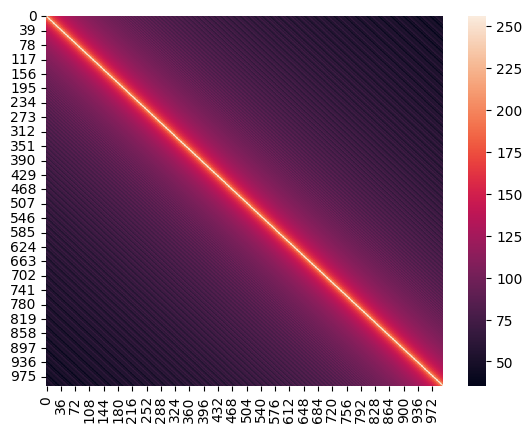

In [ ]:
dot_matrix = pos_encodings[0] @ pos_encodings[0].T
sns.heatmap(dot_matrix)
plt.show()

<center>
<div>
<img src="https://sun9-17.userapi.com/impg/gefaYRAxg9-Z_FeGLtEXsecv6BAu30fzBaOF2A/BcfIbgrYOY4.jpg?size=1120x326&quality=96&sign=7a8e392e7cb771c71acd08025dd80ea9&type=album", width="1000">
</div>

Почитать про позиционное кодирование можно тут [cite](https://arxiv.org/pdf/2010.04903.pdf)

## `3.5 Собираем модель целиком`

<!-- > Here we define a function from hyperparameters to a full model. -->

> Теперь напишем функцию, возвращающую готовую модель по гиперпараметрам

In [ ]:
def make_model(
    src_vocab, tgt_vocab, N=6, d_model=512, d_ff=2048, h=8, dropout=0.1
):
    "Helper: Construct a model from hyperparameters."
    c = copy.deepcopy
    attn = MultiHeadedAttention(h, d_model)
    ff = PositionwiseFeedForward(d_model, d_ff, dropout)
    position = PositionalEncoding(d_model, dropout)
    model = EncoderDecoder(
        Encoder(EncoderLayer(d_model, c(attn), c(ff), dropout), N),
        Decoder(DecoderLayer(d_model, c(attn), c(attn), c(ff), dropout), N),
        nn.Sequential(Embeddings(d_model, src_vocab), c(position)),
        nn.Sequential(Embeddings(d_model, tgt_vocab), c(position)),
        Generator(d_model, tgt_vocab),
    )

    # This was important from their code.
    # Initialize parameters with Glorot / fan_avg.
    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

Конечно, написание трансформера с нуля – очень полезный навык, однако, в PyTorch есть готовые блоки для этого:

`nn.Transformer` - готовая модель Transformer \\
`nn.TransformerEncoder` - стэк из N блоков кодировщика \\
`nn.TransformerDecoder` - стэк из N блоков декодировщика \\
`nn.TransformerEncoderLayer` – один блок кодировщика с MHSA и FCN \\
`nn.TransformerDecoderLayer` – один блок кодировщика с MHSA, MHCA и FCN \\

https://pytorch.org/docs/stable/nn.html#transformer-layers

## `3.6 Тестируем forward:`

<!-- > Here we make a forward step to generate a prediction of the
model. We try to use our transformer to memorize the input. As you
will see the output is randomly generated due to the fact that the
model is not trained yet. In the next tutorial we will build the
training function and try to train our model to memorize the numbers
from 1 to 10. -->

> Здесь мы делаем шаг вперед, чтобы сгенерировать прогноз модели. Мы пытаемся использовать наш кодировщик для запоминания ввода. Как вы увидите, выходные данные генерируются случайным образом из-за того, что модель еще не обучена. В следующей секции мы создадим синтетическую обучающую выборку и попробуем обучить наш трансформер запоминать числа от 1 до 10.

In [ ]:
def inference_test():
    test_model = make_model(11, 11, 2)
    test_model.eval()
    src = torch.LongTensor([[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]])
    src_mask = torch.ones(1, 1, 10)

    memory = test_model.encode(src, src_mask)
    ys = torch.zeros(1, 1).type_as(src)

    for i in range(9):
        out = test_model.decode(
            memory, src_mask, ys, subsequent_mask(ys.size(1)).type_as(src.data)
        )
        prob = test_model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.data[0]
        ys = torch.cat(
            [ys, torch.empty(1, 1).type_as(src.data).fill_(next_word)], dim=1
        )

    print("Example Untrained Model Prediction:", ys)


def run_tests():
    for _ in range(10):
        inference_test()


show_example(run_tests)

Example Untrained Model Prediction: tensor([[ 0, 10,  6,  8,  5,  4,  6, 10,  6, 10]])
Example Untrained Model Prediction: tensor([[ 0,  4, 10,  1,  4,  6,  1,  4,  8,  1]])
Example Untrained Model Prediction: tensor([[ 0,  5,  6, 10,  3,  0,  5,  5,  1,  5]])
Example Untrained Model Prediction: tensor([[0, 1, 5, 1, 5, 1, 5, 1, 5, 1]])
Example Untrained Model Prediction: tensor([[ 0, 10, 10, 10,  3,  0,  0,  0,  0,  0]])
Example Untrained Model Prediction: tensor([[ 0,  9,  9,  9,  2,  1, 10,  5,  6,  2]])
Example Untrained Model Prediction: tensor([[ 0, 10,  8, 10,  8, 10,  8, 10,  8, 10]])
Example Untrained Model Prediction: tensor([[0, 7, 9, 8, 9, 8, 9, 8, 9, 8]])
Example Untrained Model Prediction: tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])
Example Untrained Model Prediction: tensor([[0, 2, 2, 2, 2, 2, 2, 2, 2, 2]])


# `4. Процесс обучения трансформеров`

## `4.1 Вспомогательные функии`

<!-- This section describes the training regime for our models. -->
В этой секции опишем процедуру обучения трансформера.
Ниже описаны вспомогательные функции для обучения.

### Batches and Masking

In [ ]:
class Batch:
    """
    Объект для хранения батча (пакета) данных и соответствующих масок
    в процессе обучения модели Transformer.
    """

    def __init__(self, src, tgt=None, pad=2):  # По умолчанию 2 используется для токена <blank>/<pad>
        """
        Инициализация батча, разделение целевой последовательности и создание масок.

        Аргументы:
            src: Тензор исходного текста [batch_size, src_len]
            tgt: Опциональный тензор целевого текста [batch_size, tgt_len]
            pad: Индекс токена заполнения (padding), который нужно игнорировать
        """
        self.src = src

        # Создаем маску для исходного текста (src_mask).
        # (src != pad) возвращает True для значащих токенов и False для паддингов.
        # unsqueeze(-2) добавляет предпоследнюю размерность для совместимости с механизмом внимания.
        # Размерность src_mask: [batch_size, 1, src_len]
        self.src_mask = (src != pad).unsqueeze(-2)

        if tgt is not None:
            # В процессе обучения Transformer использует подход Teacher Forcing.
            # Мы разделяем целевую последовательность (tgt) на вход декодера и правильные ответы:

            # self.tgt — это вход в декодер (все токены, кроме ПОСЛЕДНЕГО).
            # Пример: если фраза "Я люблю машинное обучение <eos>", то на вход идет "Я люблю машинное обучение".
            self.tgt = tgt[:, :-1]

            # self.tgt_y — это то, что модель должна предсказать (все токены, кроме ПЕРВОГО).
            # Пример: для входа выше правильным ответом будет "люблю машинное обучение <eos>".
            self.tgt_y = tgt[:, 1:]

            # Создаем стандартную маску для декодера, которая скрывает паддинги и будущие токены
            self.tgt_mask = self.make_std_mask(self.tgt, pad)

            # Считаем общее количество реальных токенов (не паддингов) в правильных ответах.
            # Это число используется для корректного масштабирования функции потерь (loss).
            self.ntokens = (self.tgt_y != pad).data.sum()

    @staticmethod
    def make_std_mask(tgt, pad):
        """
        Создает комбинированную маску для целевой последовательности:
        скрывает как токены заполнения (padding), так и будущие слова (subsequent tokens).
        """
        # 1. Маска паддингов: выделяем значащие токены в целевой последовательности.
        # Размерность: [batch_size, 1, tgt_len]
        tgt_mask = (tgt != pad).unsqueeze(-2)

        # 2. Маска будущего времени (causal mask): получаем треугольную матрицу с помощью subsequent_mask.
        # subsequent_mask(tgt.size(-1)) возвращает матрицу [1, tgt_len, tgt_len].
        # type_as(...) приводит логический тип треугольной маски к типу маски паддингов.
        #
        # 3. Объединяем их через логическое И (&). Токен доступен для внимания только тогда,
        # когда он НЕ является паддингом И находится в прошлом/настоящем времени относительно текущей позиции.
        # Итоговая размерность tgt_mask: [batch_size, tgt_len, tgt_len]
        tgt_mask = tgt_mask & subsequent_mask(tgt.size(-1)).type_as(
            tgt_mask.data
        )
        return tgt_mask


### Training Loop

In [ ]:
class TrainState:
    """Track number of steps, examples, and tokens processed"""

    step: int = 0  # Steps in the current epoch
    accum_step: int = 0  # Number of gradient accumulation steps
    samples: int = 0  # total # of examples used
    tokens: int = 0  # total # of tokens processed

In [ ]:
import time

def run_epoch(
    data_iter,
    model,
    loss_compute,
    optimizer,
    scheduler,
    mode="train",
    accum_iter=1,
    train_state=TrainState(),
):
    """
    Запуск одной эпохи обучения или валидации (оценки) модели.

    Аргументы:
        data_iter: Итератор по данным, возвращающий объекты Batch на каждом шаге.
        model: Наша модель EncoderDecoder.
        loss_compute: Функция или вызываемый объект для расчета ошибки и градиентов.
        optimizer: Оптимизатор весов (например, Adam).
        scheduler: Планировщик для динамического изменения шага обучения (Learning Rate).
        mode: Режим работы ("train" для обучения, "eval" или другие для валидации).
        accum_iter: Интервал аккумулирования градиентов (шаг оптимизатора делается раз в N батчей).
        train_state: Объект для сохранения глобального состояния обучения (шаги, токены, сэмплы).
    """
    start = time.time()       # Фиксируем время начала для замера скорости
    total_loss = 0            # Накопленная суммарная ошибка за всю эпоху
    total_tokens = 0          # Суммарное количество обработанных токенов за всю эпоху
    tokens = 0                # Счетчик реальных токенов для локального замера скорости (каждые 40 шагов)
    n_accum = 0               # Счетчик фактически выполненных обновлений весов

    # Итерируемся по всем батчам в датасете
    for i, batch in enumerate(data_iter):
        # 1. Прямой проход модели (Forward pass)
        # Передаем исходные и целевые последовательности вместе с их масками
        out = model.forward(
            batch.src, batch.tgt, batch.src_mask, batch.tgt_mask
        )

        # 2. Расчет функции потерь
        # loss: числовое значение ошибки для логирования
        # loss_node: тензор с ошибкой, по которому будет считаться backward()
        loss, loss_node = loss_compute(out, batch.tgt_y, batch.ntokens)

        # 3. Фаза обновления параметров (только в режиме обучения)
        if mode == "train" or mode == "train+log":
            # Вычисляем градиенты методом обратного распространения ошибки
            loss_node.backward()

            # Обновляем глобальную статистику в train_state
            train_state.step += 1
            train_state.samples += batch.src.shape[0]  # Количество предложений в батче
            train_state.tokens += batch.ntokens        # Количество значащих токенов в батче

            # Реализация Gradient Accumulation (Аккумулирование градиентов):
            # Позволяет имитировать большой размер батча на слабых видеокартах.
            # Градиенты складываются на каждом шаге backward(), но веса обновляются только раз в `accum_iter` шагов.
            if i % accum_iter == 0:
                optimizer.step()                     # Обновляем веса модели
                optimizer.zero_grad(set_to_none=True) # Очищаем градиенты (set_to_none экономит память)
                n_accum += 1
                train_state.accum_step += 1

            # Шаг планировщика скорости обучения (вызывается на каждом батче)
            scheduler.step()

        # Накапливаем общую статистику для возврата из функции
        total_loss += loss
        total_tokens += batch.ntokens
        tokens += batch.ntokens  # Локальный счетчик токенов для вывода в консоль

        # 4. Логирование прогресса (каждые 40 батчей и только при обучении)
        if i % 40 == 1 and (mode == "train" or mode == "train+log"):
            lr = optimizer.param_groups[0]["lr"]  # Получаем текущий Learning Rate
            elapsed = time.time() - start         # Вычисляем прошедшее время

            # Выводим среднюю ошибку на токен, скорость обработки (токенов в секунду) и текущий LR
            print(
                (
                    " | Loss: %6.2f "
                    + "| Tokens / Sec: %7.1f | Learning Rate: %6.1e"
                )
                % (loss / batch.ntokens, tokens / elapsed, lr)
            )
            # Сбрасываем локальные счетчики времени и токенов для следующего замера
            start = time.time()
            tokens = 0

        # Явно очищаем ссылки на промежуточные тензоры потерь для освобождения памяти GPU
        del loss
        del loss_node

    # Возвращаем среднюю ошибку на один токен за всю эпоху и обновленное состояние train_state
    return total_loss / total_tokens, train_state


## `4.2 Обучающая выборка`

<!-- We trained on the standard WMT 2014 English-German dataset
consisting of about 4.5 million sentence pairs.  Sentences were
encoded using byte-pair encoding, which has a shared source-target
vocabulary of about 37000 tokens. For English-French, we used the
significantly larger WMT 2014 English-French dataset consisting of
36M sentences and split tokens into a 32000 word-piece vocabulary.


Sentence pairs were batched together by approximate sequence length.
Each training batch contained a set of sentence pairs containing
approximately 25000 source tokens and 25000 target tokens. -->

В работе Attention is all you need обучение производилось на стандартном англо-немецком наборе данных WMT 2014, состоящем примерно из 4,5 миллионов пар предложений. Предложения были закодированы с использованием byte-pair encoding. Получившийся словарь имеет около **37 000** токенов. Также модель обучалась на англо-французском датасете. Был использован значительно больший англо-французский набор данных WMT 2014, состоящий из 36 миллионов предложений и разделенных токенов на словарь из 32000 слов.

Пары предложений были объединены в батчи по приблизительной длине последовательности. Каждый батч состоял из набора пар предложений, содержащих примерно 25000 исходных и 25000 целевых токенов.

## `4.3 Hardware and Schedule`

<!-- We trained our models on one machine with 8 NVIDIA P100 GPUs.  For
our base models using the hyperparameters described throughout the
paper, each training step took about 0.4 seconds.  We trained the
base models for a total of 100,000 steps or 12 hours. For our big
models, step time was 1.0 seconds.  The big models were trained for
300,000 steps (3.5 days). -->

Модели обучались на одной машине с 8 графическими процессорами NVIDIA P100. Для base-моделей, использующих описанные в статье гиперпараметры, каждый шаг обучения занимал около 0,4 секунд. Они обучались в общей сложности 100 000 шагов или 12 часов. Для больших моделей время шага составляло 1,0 секунды. Large-модели были обучены за 300 000 шагов (3,5 дня).

## `4.4 Optimizer`

<!-- We used the Adam optimizer [(cite)](https://arxiv.org/abs/1412.6980)
with $\beta_1=0.9$, $\beta_2=0.98$ and $\epsilon=10^{-9}$.  We
varied the learning rate over the course of training, according to
the formula: -->
В статье использовался Adam [(cite)](https://arxiv.org/abs/1412.6980) с параметрами $\beta_1=0.9$, $\beta_2=0.98$ и $\epsilon=10^{-9}$. Learning rate варьировался по следующей формуле:

$$
lrate = d_{\text{model}}^{-0.5} \cdot
  \min({step\_num}^{-0.5},
    {step\_num} \cdot {warmup\_steps}^{-1.5})
$$

<!-- This corresponds to increasing the learning rate linearly for the
first $warmup\_steps$ training steps, and decreasing it thereafter
proportionally to the inverse square root of the step number.  We
used $warmup\_steps=4000$. -->

Это соответствует линейному увеличению learning rate для первых $warmup\_steps$ шагов. Далее learning rate уменьшается пропорционально обратному квадратному корню из номера шага. Использовался $warmup\_steps=4000$.

In [ ]:
def rate(step, model_size, factor, warmup):
    """
    we have to default the step to 1 for LambdaLR function
    to avoid zero raising to negative power.
    """
    if step == 0:
        step = 1
    return factor * (
        model_size ** (-0.5) * min(step ** (-0.5), step * warmup ** (-1.5))
    )

In [ ]:
def example_learning_schedule():
    opts = [
        [512, 1, 4000],  # example 1
        [512, 1, 8000],  # example 2
        [256, 1, 4000],  # example 3
    ]

    dummy_model = torch.nn.Linear(1, 1)
    learning_rates = []

    # we have 3 examples in opts list.
    for idx, example in enumerate(opts):
        # run 20000 epoch for each example
        optimizer = torch.optim.Adam(
            dummy_model.parameters(), lr=1, betas=(0.9, 0.98), eps=1e-9
        )
        lr_scheduler = LambdaLR(
            optimizer=optimizer, lr_lambda=lambda step: rate(step, *example)
        )
        tmp = []
        # take 20K dummy training steps, save the learning rate at each step
        for step in range(20000):
            tmp.append(optimizer.param_groups[0]["lr"])
            optimizer.step()
            lr_scheduler.step()
        learning_rates.append(tmp)

    learning_rates = torch.tensor(learning_rates)

    # Enable altair to handle more than 5000 rows
    alt.data_transformers.disable_max_rows()

    opts_data = pd.concat(
        [
            pd.DataFrame(
                {
                    "Learning Rate": learning_rates[warmup_idx, :],
                    "model_size_warmup": ["512:4000", "512:8000", "256:4000"][
                        warmup_idx
                    ],
                    "step": range(20000),
                }
            )
            for warmup_idx in [0, 1, 2]
        ]
    )

    return (
        alt.Chart(opts_data)
        .mark_line()
        .properties(width=600)
        .encode(x="step", y="Learning Rate", color="model_size_warmup:N")
        .interactive()
    )


example_learning_schedule()

Output hidden; open in https://colab.research.google.com to view.

## `4.5 Регуляризация`

### Label Smoothing

<!-- During training, we employed label smoothing of value
$\epsilon_{ls}=0.1$ [(cite)](https://arxiv.org/abs/1512.00567).
This hurts perplexity, as the model learns to be more unsure, but
improves accuracy and BLEU score. -->

Во время обучения мы используем label smoothing со значением $\epsilon_{ls}=0.1$ [(cite)](https://arxiv.org/abs/1512.00567). Это уменьшает перплексию, поскольку модель учится быть более неуверенной, но при этом повышается точность и значение метрики BLEU на реальных данных.


<!-- > We implement label smoothing using the KL div loss. Instead of
> using a one-hot target distribution, we create a distribution that
> has `confidence` of the correct word and the rest of the
> `smoothing` mass distributed throughout the vocabulary. -->

> Реализуем label smoothing с помощью `nn.KLDivLoss`.

In [ ]:
import torch
import torch.nn as nn

class LabelSmoothing(nn.Module):
    """
    Реализация механизма сглаживания меток (Label Smoothing).

    Вместо жесткого распределения «one-hot» (где правильное слово имеет вероятность 1.0,
    а остальные — 0.0), этот слой перераспределяет часть вероятности (smoothing) поровну
    между всеми неправильными словами. Это предотвращает переобучение модели и делает её
    менее «самоуверенной», улучшая качество генерации.
    """

    def __init__(self, size, padding_idx, smoothing=0.0):
        """
        Инициализация параметров сглаживания меток.

        Аргументы:
            size: Размер словаря (количество классов/токенов в vocab).
            padding_idx: Индекс токена заполнения (pad), который нужно игнорировать.
            smoothing: Доля уверенности, которая забирается у правильного класса и
                       распределяется по другим (например, 0.1).
        """
        super(LabelSmoothing, self).__init__()
        # В качестве функции потерь используется Дивергенция Кульбака-Лейблера (KLDivLoss).
        # Она идеально подходит для вычисления расстояния между двумя распределениями вероятностей.
        # Ожидает, что входные данные х уже пропущены через log_softmax.
        self.criterion = nn.KLDivLoss(reduction="sum")

        self.padding_idx = padding_idx
        self.confidence = 1.0 - smoothing  # Оставшаяся уверенность для правильного токена
        self.smoothing = smoothing
        self.size = size
        self.true_dist = None              # Будет хранить целевое сглаженное распределение

    def forward(self, x, target):
        """
        Прямой проход для расчета сглаженной функции потерь.

        Аргументы:
            x: Логарифмы вероятностей от модели (выход Generator) [batch_size * seq_len, vocab_size]
            target: Истинные индексы токенов (правильные ответы) [batch_size * seq_len]
        """
        # Убеждаемся, что размерность предсказаний по оси классов совпадает с размером словаря
        assert x.size(1) == self.size

        # 1. Создаем матрицу "целевого распределения" true_dist той же формы, что и x.
        # Используем detach().clone(), чтобы градиенты через этот целевой тензор не текли.
        true_dist = x.detach().clone()

        # 2. Заполняем всю матрицу базовым сглаженным значением ошибки.
        # Делим на (size - 2), потому что мы распределяем сглаживание по всем токенам словаря,
        # ИСКЛЮЧАЯ правильный токен и токен паддинга (size - 2).
        true_dist.fill_(self.smoothing / (self.size - 2))

        # 3. На места истинных классов (заданных в target) записываем значение уверенности confidence.
        # scatter_ распределяет значения вдоль указанной оси (1 — ось классов) по индексам из target.
        true_dist.scatter_(1, target.detach().unsqueeze(1), self.confidence)

        # 4. Обнуляем вероятность для токена паддинга (pad) во всех строках матрицы,
        # так как модель не должна генерировать или штрафоваться за паддинги.
        true_dist[:, self.padding_idx] = 0

        # 5. Находим строки, где истинным целевым токеном является padding_idx.
        mask = torch.nonzero(target.detach() == self.padding_idx, as_tuple=False)

        # 6. Если такие строки найдены, полностью зануляем для них целевое распределение.
        # Таким образом, эти позиции не внесут вклад в расчет финального лосса KL-дивергенции.
        if mask.numel() > 0:
            true_dist.index_fill_(0, mask.squeeze(-1), 0.0)

        # Сохраняем распределение в self.true_dist (полезно для отладки или визуализации)
        self.true_dist = true_dist

        # 7. Считаем и возвращаем значение KL-дивергенции между предсказаниями модели x
        # и нашим искусственно сглаженным распределением true_dist.
        return self.criterion(x, true_dist.detach())



<!-- > Label smoothing actually starts to penalize the model if it gets
> very confident about a given choice. -->

> Label smoothing фактически начинает наказывать модель, если она становится очень уверенной в своих предсказаниях.

$$
L' = \sum_{i=1}^{n} \big[(1-\epsilon_{ls})KL(p, q_{\theta}) + \epsilon_{ls}KL(u, q_{\theta})\big] \\
u \sim U([1 \dots K])
$$

# `5. Синтетический пример`

<!-- > We can begin by trying out a simple copy-task. Given a random set
> of input symbols from a small vocabulary, the goal is to generate
> back those same symbols. -->

> Давайте попробуем обучить нашу модель решать простую задачу. Пусть это будет задача копирования последовательности. Принимая на вход случайный набор символов из небольшого словаря, модель должна сгенерировать обратно те же самые символы.

## `5.1 Генерируем данные`

In [ ]:
def data_gen(V, batch_size, nbatches):
    "Generate random data for a src-tgt copy task."
    for i in range(nbatches):
        data = torch.randint(1, V, size=(batch_size, 10))
        data[:, 0] = 1
        src = data.requires_grad_(False).clone().detach()
        tgt = data.requires_grad_(False).clone().detach()
        # tgt = torch.flip(data, dims=[1]).requires_grad_(False).clone().detach()
        yield Batch(src, tgt, 0)

## `5.2 Loss Computation`

In [ ]:
class SimpleLossCompute:
    "A simple loss compute and train function."

    def __init__(self, generator, criterion):
        self.generator = generator
        self.criterion = criterion

    def __call__(self, x, y, norm):
        x = self.generator(x)
        sloss = (
            self.criterion(
                x.contiguous().view(-1, x.size(-1)), y.contiguous().view(-1)
            )
            / norm
        )
        return sloss.data * norm, sloss

## `5.3 Greedy Decoding`

<!-- > This code predicts a translation using greedy decoding for simplicity. -->

> Будем генерировать предсказание жадным образом.

In [ ]:
def greedy_decode(model, src, src_mask, max_len, start_symbol):
    memory = model.encode(src, src_mask)
    ys = torch.zeros(1, 1).fill_(start_symbol).type_as(src.data)
    for i in range(max_len - 1):
        out = model.decode(
            memory, src_mask, ys, subsequent_mask(ys.size(1)).type_as(src.data)
        )
        prob = model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.data[0]
        ys = torch.cat(
            [ys, torch.zeros(1, 1).type_as(src.data).fill_(next_word)], dim=1
        )
    return ys

Другой способ получить предсказание – Beam Search [cite:](https://towardsdatascience.com/foundations-of-nlp-explained-visually-beam-search-how-it-works-1586b9849a24)

In [ ]:
# Train the simple copy task.


def train_simple_model(n_epochs, **model_params):
    V = 11
    criterion = LabelSmoothing(size=V, padding_idx=0, smoothing=0.0)
    # model = make_model(V, V, N=1, h=1)
    model = make_model(V, V, **model_params)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.5, betas=(0.9, 0.98), eps=1e-9
    )
    lr_scheduler = LambdaLR(
        optimizer=optimizer,
        lr_lambda=lambda step: rate(
            step, model_size=model.src_embed[0].d_model, factor=1.0, warmup=400
        ),
    )

    batch_size = 80
    ts = TrainState()
    for epoch in range(n_epochs):
        print(f'Epoch {epoch}', end='')
        model.train()
        run_epoch(
            data_gen(V, batch_size, 20),
            model,
            SimpleLossCompute(model.generator, criterion),
            optimizer,
            lr_scheduler,
            mode="train",
        )
        model.eval()
        run_epoch(
            data_gen(V, batch_size, 5),
            model,
            SimpleLossCompute(model.generator, criterion),
            DummyOptimizer(),
            DummyScheduler(),
            mode="eval",
        )

    model.eval()
    return model

In [ ]:
model = train_simple_model(10, N=2, h=1)

Epoch 0 | Loss:   3.07 | Tokens / Sec:  1591.3 | Learning Rate: 5.5e-06
Epoch 1 | Loss:   2.07 | Tokens / Sec:  2215.6 | Learning Rate: 6.1e-05
Epoch 2 | Loss:   1.80 | Tokens / Sec:  2229.7 | Learning Rate: 1.2e-04
Epoch 3 | Loss:   1.25 | Tokens / Sec:  2156.1 | Learning Rate: 1.7e-04
Epoch 4 | Loss:   0.86 | Tokens / Sec:  2229.3 | Learning Rate: 2.3e-04
Epoch 5 | Loss:   0.58 | Tokens / Sec:  2223.7 | Learning Rate: 2.8e-04
Epoch 6 | Loss:   0.42 | Tokens / Sec:  2175.9 | Learning Rate: 3.4e-04
Epoch 7 | Loss:   0.35 | Tokens / Sec:  2041.7 | Learning Rate: 3.9e-04
Epoch 8 | Loss:   0.27 | Tokens / Sec:  2137.7 | Learning Rate: 4.5e-04
Epoch 9 | Loss:   0.27 | Tokens / Sec:  2229.0 | Learning Rate: 5.0e-04


## `5.4 Attention Visualization`

Давайте посмотрим на attention-матрицы, которые выучила наша модель.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def get_encoder_self(model, layer):
    return model.encoder.layers[layer].self_attn.attn


def get_decoder_self(model, layer):
    return model.decoder.layers[layer].self_attn.attn


def get_decoder_src(model, layer):
    return model.decoder.layers[layer].src_attn.attn

In [ ]:
src = torch.LongTensor([[1, 3, 4, 5, 6, 7, 8, 9, 8, 7, 6, 5]])
print('sourse:\t', src)
# print('target:\t', torch.flip(src, dims=[1]))
max_len = src.shape[1]
src_mask = torch.ones(1, 1, max_len)
print('pred:\t', greedy_decode(model, src, src_mask, max_len=max_len, start_symbol=1))

sourse:	 tensor([[1, 3, 4, 5, 6, 7, 8, 9, 8, 7, 6, 5]])
pred:	 tensor([[1, 3, 4, 5, 6, 7, 8, 9, 8, 6, 5, 6]])


In [ ]:
get_encoder_self(model, 0).size()

torch.Size([1, 1, 12, 12])

In [ ]:
get_decoder_src(model, 0).size()

torch.Size([1, 1, 11, 12])

In [ ]:
get_decoder_self(model, 0).size()

torch.Size([1, 1, 11, 11])

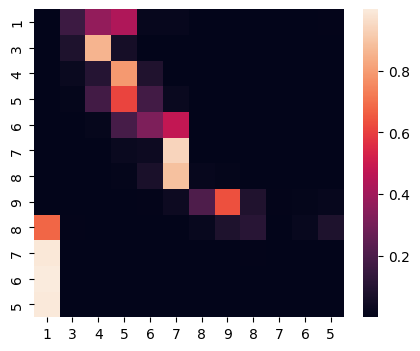

In [ ]:
# @title Encoder Self-Attention
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(get_encoder_self(model, 1)[0][0].data)
ax.set_xticklabels(src[0].tolist())
ax.set_yticklabels(src[0].tolist())
plt.show()

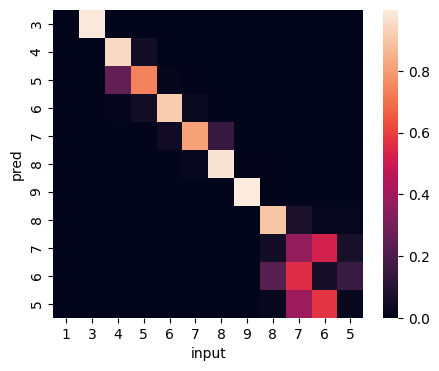

In [ ]:
# @title Decoder Cross-Attention
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(get_decoder_src(model, 0)[0][0].data)
ax.set_xticklabels(src[0].tolist())
ax.set_xlabel('input')
ax.set_yticklabels(src[0, 1:].tolist())
ax.set_ylabel('pred')
plt.show()

## Часть B. Почему base-модель и instruct-модель отвечают по-разному

- сначала сравниваем **pre-trained** и **instruction-following** модель;
- затем показываем, как chat template меняет формат запроса;
- после этого переходим к дообучению модели под конкретное поведение.

In [ ]:
# Импорты уже сделаны в первой setup-ячейке.
# Здесь оставляем только модели и утилиты для LLM-блоков семинара.

def check_target_module_exists(config, module_name: str) -> bool:
    return any(module_name.endswith(target_name) for target_name in config.target_modules)

# Сравнение pre-trained и instruction following моделей

#### Pre-trained model

In [ ]:
pl = make_text_generation_pipeline(BASE_MODEL_ID)

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/269M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
prompt = """What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]
"""

print(prompt)

What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]



In [ ]:
model_pred = pl(
    prompt,
    max_new_tokens=64,
    return_full_text=True,
    do_sample=True,
)

print(extract_generated_text(model_pred))

Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.
Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]

The code runs in less than 1 second, and it’s good enough for our purpose. The only difference is that we’re doing a loop instead of changing each element in the list in a for loop.

The next code creates a new variable (a list) called k, and increments it


In [ ]:
del pl

gc.collect()
torch.cuda.empty_cache()

#### Instruction following model

In [ ]:
pl = make_text_generation_pipeline(INSTRUCT_MODEL_ID)

config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/269M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
prompt = """What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]
"""

print(prompt)

What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]



In [ ]:
model_pred = pl(
    prompt,
    max_new_tokens=256,
    return_full_text=True,
    do_sample=True,
)

print(extract_generated_text(model_pred))

Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


What is the purpose of the list C in the code below?
def binomial_coefficient(n, r):
    C = [0 for i in range(r + 1)];
    C[0] = 1;
    for i in range(1, n + 1):
        j = min(i, r);
        while j > 0:
        C[j] += C[j - 1];
        j -= 1;
    return C[r]

print(binomial_coefficient(7, 3))
```


Подготавливаем промпт в формате ...

In [ ]:
system_prompt = "You are a precise and efficient code assistant. Analyze user requests carefully, provide clean, idiomatic code with best practices, and explain concepts concisely. Prioritize correctness, performance, and readability. Highlight edge cases and errors proactively. Tailor responses to the user’s expertise level."

print(f"{system_prompt=}")

instruction = [
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": prompt},
]

system_prompt='You are a precise and efficient code assistant. Analyze user requests carefully, provide clean, idiomatic code with best practices, and explain concepts concisely. Prioritize correctness, performance, and readability. Highlight edge cases and errors proactively. Tailor responses to the user’s expertise level.'


In [ ]:
model_pred = pl(
    instruction,
    max_new_tokens=256,
    return_full_text=True,
    do_sample=True,
)

print(extract_generated_text(model_pred))

Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


The list `C` is defined in the code as a 2-dimensional array `C` of size `2 * r + 1`, where `r` is the upper half of the range, and `n` is the lower half. This 2-dimensional array is initialized to store the binomial coefficients.

The `binomial_coefficient` function takes two arguments: `n`, the number of terms in the expansion, and `r`, the range of the terms. The function initializes the array `C` with the values 0 and 1, which represent the first and last terms, respectively.

The function then iterates over the range from `n - 1` to `r` to calculate the binomial coefficients. The function uses a `for` loop to iterate from `r` to `n - 1` and updates the `C` array with the corresponding binomial coefficients.

Finally, the function returns the `C` array, which contains the binomial coefficients for the given range of terms.

The `binomial_coefficient` function is designed to efficiently calculate the binomial coefficients, taking into account the constraints imposed by the range. Th

In [ ]:
del pl

gc.collect()
torch.cuda.empty_cache()

# Задачи NLP

<div style="max-width:1000px;margin-right: auto; margin-right: 0;">
    <img alt="Классификация задач NLP" src="https://media.mobidev.biz/2024/12/nlp-tasks.png?strip=all&lossy=1&ssl=1&_gl=1*5860h5*_gcl_au*MjYwODA2Nzc0LjE3NDM0NDc1MDc.">
</div>

# Дообучаем модель генерировать анекдоты

#### Загружаем датасет

In [ ]:
dataset = load_dataset("igorktech/anekdots_dialogs")

dataset

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/41.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100834 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['original', 'parsed', 'total_mark', 'date', 'downvote', 'total_votes', 'upvote', 'hash', 'alpha_frac', 'LDR', 'days_since_publication', 'time_decay', 'LDR_time_decay'],
        num_rows: 100834
    })
})

In [ ]:
dataset = dataset.remove_columns(
    [col for col in dataset.column_names['train'] if col not in ('original', 'upvote')]
)

dataset

DatasetDict({
    train: Dataset({
        features: ['original', 'upvote'],
        num_rows: 100834
    })
})

#### Загружаем модель и токенизатор

In [ ]:
device = DEVICE

tokenizer, model = load_causal_lm_and_tokenizer(INSTRUCT_MODEL_ID, device=device)
model.eval()

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 576, padding_idx=2)
    (layers): ModuleList(
      (0-29): 30 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=576, out_features=576, bias=False)
          (k_proj): Linear(in_features=576, out_features=192, bias=False)
          (v_proj): Linear(in_features=576, out_features=192, bias=False)
          (o_proj): Linear(in_features=576, out_features=576, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=576, out_features=1536, bias=False)
          (up_proj): Linear(in_features=576, out_features=1536, bias=False)
          (down_proj): Linear(in_features=1536, out_features=576, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((576,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((576,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((576,), eps=1e-05)
    (r

#### Генерируем анекдоты

In [ ]:
system_prompt = "Вы профессиональный генератор анекдотов на русском языке. Создавайте оригинальные, культурно-релевантные шутки с использованием игры слов, иронии и кратких историй. Избегайте запрещенных тем, стереотипов и оскорбительного контента. Адаптируйте стиль под аудиторию (семейный, сатирический и т.д.), если не указано иное."

user_prompt = "Сгенерируй анекдот про Петьку и Василия Ивановича"

print(f"{system_prompt=}\n\n{user_prompt=}")

instruction = [
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": user_prompt},
]

system_prompt='Вы профессиональный генератор анекдотов на русском языке. Создавайте оригинальные, культурно-релевантные шутки с использованием игры слов, иронии и кратких историй. Избегайте запрещенных тем, стереотипов и оскорбительного контента. Адаптируйте стиль под аудиторию (семейный, сатирический и т.д.), если не указано иное.'

user_prompt='Сгенерируй анекдот про Петьку и Василия Ивановича'


In [ ]:
pl = make_text_generation_pipeline(model, tokenizer=tokenizer)

In [ ]:
model_pred = pl(
    instruction,
    max_new_tokens=128,
    return_full_text=True,
    do_sample=True,
)

print(extract_generated_text(model_pred))

Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Оставь деньга: Петьку и Василия Ивановича. Одной проблемы по большей размерами, и с разработчиком, если они были доступен на экране. Вскорее, Петьку и Василия Иванови


#### Сомнительно, но окей... Давайте дообучать

### Пишем свою LoRA

Создаем слой, на который будут заменяться линейные слои модели

[Исходники PEFT](https://github.com/huggingface/peft/tree/v0.18.1/src/peft/tuners/lora)

In [ ]:
# # del model
# # gc.collect()

# tokenizer = AutoTokenizer.from_pretrained(INSTRUCT_MODEL_ID)
# model = AutoModelForCausalLM.from_pretrained(INSTRUCT_MODEL_ID)

# if tokenizer.pad_token is None:
#     tokenizer.pad_token = tokenizer.eos_token

In [ ]:
def get_layer(model, name):
    layer = model
    for attr in name.split("."):
        layer = getattr(layer, attr)
    return layer

def set_layer(model, name, layer):
    try:
        attrs, name = name.rsplit(".", 1)
        model = get_layer(model, attrs)
    except ValueError:
        pass
    setattr(model, name, layer)

def get_submodules(model, key):
    parent = model.get_submodule(".".join(key.split(".")[:-1]))
    target_name = key.split(".")[-1]
    target = model.get_submodule(key)
    return parent, target, target_name

def print_num_trainable(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frac = (float(trainable_params) / total_params) * 100

    print(f"trainable: {trainable_params}  |  total: {total_params}  |  trainable(%): {frac:.6f}")

In [ ]:
class LoRALayer(nn.Module):
    def __init__(self, base_layer: nn.Linear, r: int, lora_alpha: int, dropout_p: float = 0.0):
        super().__init__()

        self.in_features = base_layer.in_features
        self.out_features = base_layer.out_features
        self.r = r
        self.lora_alpha = lora_alpha
        self.scale = self.lora_alpha / r
        self._enabled = True
        self._merged = False

        self.base_layer = base_layer
        self.lora_A = nn.Linear(self.in_features, r, bias=False, device=base_layer.weight.device)
        self.lora_B = nn.Linear(r, self.out_features, bias=False, device=base_layer.weight.device)
        self.lora_dropout = nn.Dropout(dropout_p).to(base_layer.weight.device)
        self.reset_parameters()

    @torch.no_grad()
    def reset_parameters(self):
        nn.init.kaiming_uniform_(self.lora_A.weight, a=np.sqrt(5))
        nn.init.zeros_(self.lora_B.weight)

    def enable_adapters(self, enable: bool = True):
        self._enabled = enable

    def forward(self, x):
        if self._enabled:
            y = self.lora_dropout(x)
            y = self.lora_A(y)
            y = self.lora_B(y)

            y = self.scale * y + self.base_layer(x)
        else:
            y = self.base_layer(x)

        return y

    @torch.no_grad()
    def merge(self) -> None:
        if self._merged:
            return

        self._merged = True
        W_0 = self.base_layer.weight # (out_f, in_f)
        A = self.lora_A.weight       # (r,     in_f)
        B = self.lora_B.weight       # (out_f, r)

        delta_W = self.scale * (B @ A).to(W_0.dtype)
        self.base_layer.weight.data = W_0 + delta_W

    @torch.no_grad()
    def unmerge(self) -> None:
        if not self._merged:
            return

        self._merged = False
        W_0 = self.base_layer.weight # (out_f, in_f)
        A = self.lora_A.weight       # (r,     in_f)
        B = self.lora_B.weight       # (out_f, r)

        delta_W = self.scale * (B @ A).to(W_0.dtype)
        self.base_layer.weight.data = W_0 - delta_W

In [ ]:
# del LoRALayer
# del model
# del model_adapter

# gc.collect()

In [ ]:
from dataclasses import dataclass

@dataclass
class LoRAConfig:
    r: int
    lora_dropout: float
    lora_alpha: float
    target_modules: list[str]

In [ ]:
lora_config = LoRAConfig(
    r=16,
    lora_dropout=0.05,
    lora_alpha=32,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj']
)

lora_config

LoRAConfig(r=16, lora_dropout=0.05, lora_alpha=32, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'])

In [ ]:
class LoRAModel(nn.Module):
    def __init__(self, model, lora_config: LoRAConfig):
        super().__init__()

        self.model = model
        self.config = model.config
        self.lora_config = lora_config
        self.generation_config = model.generation_config

        self._setup_adapters()

    def __getattr__(self, name):
        try:
            return super().__getattr__(name)
        except AttributeError:
            return getattr(self.model, name)

    @property
    def device(self):
        return self.model.device

    @property
    def dtype(self):
        return self.model.dtype

    def can_generate(self):
        return self.model.can_generate()

    def _setup_adapters(self) -> None:
        for _, param in self.model.named_parameters():
            param.requires_grad = False

        for name, module in list(self.model.named_modules()):
            if not check_target_module_exists(self.lora_config, name):
                continue

            if not isinstance(module, nn.Linear):
                continue

            kwargs = {
                "r": self.lora_config.r,
                "lora_alpha": self.lora_config.lora_alpha,
                "dropout_p": self.lora_config.lora_dropout,
            }

            lora_layer = LoRALayer(module, **kwargs)
            set_layer(self.model, name, lora_layer)

    def enable_adapters(self):
        for _, layer in self.named_modules():
            if isinstance(layer, LoRALayer):
                layer.enable_adapters(True)

    def disable_adapters(self):
        for _, layer in self.named_modules():
            if isinstance(layer, LoRALayer):
                layer.enable_adapters(False)

    def gradient_checkpointing_enable(self, *args, **kwargs):
        if hasattr(self.model, "gradient_checkpointing_enable"):
            return self.model.gradient_checkpointing_enable(*args, **kwargs)

    def gradient_checkpointing_disable(self):
        if hasattr(self.model, "gradient_checkpointing_disable"):
            return self.model.gradient_checkpointing_disable()

    def prepare_inputs_for_generation(self, *args, **kwargs):
        return self.model.prepare_inputs_for_generation(*args, **kwargs)

    def save_pretrained(self, *args, **kwargs):
        return self.model.save_pretrained(*args, **kwargs)

    def unload_and_optionally_merge(self, merge: bool = True, progressbar: bool = False) -> nn.Module:
        desc = "Unloading " + ("and merging " if merge else "") + "model"
        named_modules = list(
            filter(lambda p: isinstance(p[1], LoRALayer), self.named_modules())
        )

        for name, lora_layer in tqdm.tqdm(named_modules, disable=not progressbar, desc=desc):
            parent, target, target_name = get_submodules(self, name)

            if merge:
                lora_layer.merge()
            set_layer(parent, target_name, lora_layer.base_layer)

        return self.model

    def forward(self, *args, **kwargs):
        return self.model(*args, **kwargs)

    def generate(self, *args, **kwargs):
        return self.model.generate(*args, **kwargs)

In [ ]:
# model_adapter.unload_and_optionally_merge(False)

In [ ]:
model_adapter = LoRAModel(model, lora_config)

model_adapter

LoRAModel(
  (model): LlamaForCausalLM(
    (model): LlamaModel(
      (embed_tokens): Embedding(49152, 576, padding_idx=2)
      (layers): ModuleList(
        (0-29): 30 x LlamaDecoderLayer(
          (self_attn): LlamaAttention(
            (q_proj): LoRALayer(
              (base_layer): Linear(in_features=576, out_features=576, bias=False)
              (lora_A): Linear(in_features=576, out_features=16, bias=False)
              (lora_B): Linear(in_features=16, out_features=576, bias=False)
              (lora_dropout): Dropout(p=0.05, inplace=False)
            )
            (k_proj): LoRALayer(
              (base_layer): Linear(in_features=576, out_features=192, bias=False)
              (lora_A): Linear(in_features=576, out_features=16, bias=False)
              (lora_B): Linear(in_features=16, out_features=192, bias=False)
              (lora_dropout): Dropout(p=0.05, inplace=False)
            )
            (v_proj): LoRALayer(
              (base_layer): Linear(in_features=5

In [ ]:
print_num_trainable(model_adapter)

trainable: 1843200  |  total: 136358208  |  trainable(%): 1.351734


In [ ]:
# from peft import get_peft_model, LoraConfig as PeftLoRAConfig, TaskType

In [ ]:
# peft_lora_config = PeftLoRAConfig(
#     task_type=TaskType.CAUSAL_LM,
#     inference_mode=False,
#     r=16,
#     lora_dropout=0.05,
#     lora_alpha=32,
#     target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj']
# )

# model_adapter =  get_peft_model(model, peft_lora_config)

In [ ]:
# peft_model_adapter.unload()

In [ ]:
model_adapter = model_adapter.to(torch.bfloat16)

In [ ]:
adapter_demo_text = generate_with_model(
    model_adapter,
    tokenizer,
    "Hello",
    max_new_tokens=16,
    do_sample=False,
)

adapter_demo_text

",\n\nI'm glad you're enjoying the experience. I hope you find"

In [ ]:
print(adapter_demo_text)

,

I'm glad you're enjoying the experience. I hope you find


### SFT: legacy collator как reference и нативный prompt/completion формат TRL

In [ ]:
from transformers import DataCollatorForLanguageModeling
from typing import Union, Any

In [ ]:
# Legacy reference: с актуальным TRL этот collator ниже больше не обязателен,
# если dataset подготовлен в формате prompt/completion.

class DataCollatorForCompletionOnlyLM(DataCollatorForLanguageModeling):
    """
    Data collator used for completion tasks. It ensures that all the tokens of the labels are set to an 'ignore_index'
    when they do not come from the assistant. This ensure that the loss is only
    calculated on the completion made by the assistant.

    Args:
        response_template (`Union[str, list[int]]`): the template form that indicates the start of the response, typically something like
            '### Response:\n'. It can also be passed as tokenized ids, which can be useful when using a tokenizer that encodes the response
            differently if it does not have proper context.
        instruction_template (`Union[str, list[int]]`): the template form that indicates the start of the human instruction, typically something like
            '### Human:\n'. Useful for assistant-style conversation datasets. It can also be passed as tokenized ids.
        mlm (`bool`, *optional*, defaults to `False`): Whether to use masked language modeling in the underlying
            `DataCollatorForLanguageModeling` class. Note that this option currently has no effect but is present
             for flexibility and backwards-compatibility.
        ignore_index (`int`, *optional*, defaults to `-100`):
            The index to use to ignore the initial tokens with
    """

    def __init__(
        self,
        response_template: str,
        # instruction_template: str = None,
        *args,
        mlm: bool = False,
        ignore_index: int = -100,
        **kwargs,
    ):
        super().__init__(*args, mlm=mlm, **kwargs)

        # self.instruction_template = instruction_template
        # self.instruction_token_ids = self.tokenizer.encode(self.instruction_template, add_special_tokens=False)

        self.response_template = response_template
        self.response_token_ids = self.tokenizer.encode(self.response_template, add_special_tokens=False)

        self.instruction_template = None
        if not self.mlm and self.instruction_template and self.tokenizer.pad_token_id == self.tokenizer.eos_token_id:
            warnings.warn(
                "The pad_token_id and eos_token_id values of this tokenizer are identical. "
                "If you are planning for multi-turn training, "
                "it can result in the model continuously generating questions and answers without eos token. "
                "To avoid this, set the pad_token_id to a different value.",
                UserWarning,
            )

        self.ignore_index = ignore_index

    def torch_call(self, examples: list[Union[list[int], Any, dict[str, Any]]]) -> dict[str, Any]:
        batch = super().torch_call(examples)

        for i in range(len(examples)):
            response_token_ids_start_idx = None

            for idx in np.where(batch["labels"][i] == self.response_token_ids[0])[0]:
                # `response_token_ids` is `'### Response:\n'`, here we are just making sure that the token IDs match
                if (
                    self.response_token_ids
                    == batch["labels"][i][idx : idx + len(self.response_token_ids)].tolist()
                ):
                    response_token_ids_start_idx = idx

            if response_token_ids_start_idx is None:
                warnings.warn(
                    f"Could not find response key `{self.response_template}` in the following instance: "
                    f"{self.tokenizer.decode(batch['input_ids'][i])}. This instance will be ignored in loss "
                    "calculation. Note, if this happens often, consider increasing the `max_length`.",
                    UserWarning,
                )
                batch["labels"][i, :] = self.ignore_index
            else:
                response_token_ids_end_idx = response_token_ids_start_idx + len(self.response_token_ids)

                # Make pytorch loss function ignore all tokens up through the end of the response key
                batch["labels"][i, :response_token_ids_end_idx] = self.ignore_index

        return batch

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['original', 'upvote'],
        num_rows: 100834
    })
})

In [ ]:
def get_instructions(example):
    system_prompt = "Вы профессиональный генератор анекдотов на русском языке. Создавайте оригинальные, культурно-релевантные шутки с использованием игры слов, иронии и кратких историй. Избегайте запрещенных тем, стереотипов и оскорбительного контента. Адаптируйте стиль под аудиторию (семейный, сатирический и т.д.), если не указано иное."
    user_prompt = "Сгенерируй смешной анекдот"
    assistant_answer = example["original"]

    return {
        "prompt": [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt},
        ],
        "completion": [
            {"role": "assistant", "content": assistant_answer},
        ],
    }

In [ ]:
dataset = dataset["train"].sort("upvote", reverse=True)

sample_size = min(2_000, len(dataset))
test_size = min(64, max(1, sample_size // 20))

dataset = dataset.select(range(sample_size))
dataset = dataset.map(get_instructions, remove_columns=dataset.column_names)
dataset = dataset.train_test_split(test_size=test_size, seed=42)

dataset

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 1936
    })
    test: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 64
    })
})

In [ ]:
training_args = SFTConfig(
    output_dir="./SFT_sem",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=32,
    fp16=(DEVICE == "cuda" and not torch.cuda.is_bf16_supported()),
    bf16=(DEVICE == "cuda" and torch.cuda.is_bf16_supported()),
    lr_scheduler_type="linear",
    warmup_ratio=0.1,
    max_steps=SFT_DEMO_MAX_STEPS,
    learning_rate=1e-4,
    weight_decay=0.01,
    eval_strategy="steps",
    eval_steps=SFT_DEMO_MAX_STEPS,
    logging_steps=1,
    seed=42,
    data_seed=42,
    report_to="none",
    save_strategy="no",
    max_length=1024,
    completion_only_loss=True,
    gradient_checkpointing=False,
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
print(
    "Используем conversational prompt/completion dataset — в актуальном TRL loss на completion "
    "считается нативно, поэтому кастомный collator выше остается только как reference."
)

Используем conversational prompt/completion dataset — в актуальном TRL loss на completion считается нативно, поэтому кастомный collator выше остается только как reference.


In [ ]:
trainer = SFTTrainer(
    model=model_adapter,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    processing_class=tokenizer,
)

Tokenizing train dataset:   0%|          | 0/1936 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1936 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

In [ ]:
trainer.train()

Step,Training Loss,Validation Loss
10,2.186566,No log


TrainOutput(global_step=10, training_loss=2.2883514881134035, metrics={'train_runtime': 55.3343, 'train_samples_per_second': 5.783, 'train_steps_per_second': 0.181, 'total_flos': 93153288843648.0, 'train_loss': 2.2883514881134035})

## Часть B. PEFT в HuggingFace: LoRA, AdaLoRA, QLoRA, Prompt Tuning, Prefix Tuning

Ниже идеи PEFT показаны уже через библиотеку `peft`:
- классический LoRA;
- LoRA на нескольких целевых модулях;
- AdaLoRA;
- QLoRA;
- Prompt Tuning и Prefix Tuning.

Полезно проходить этот блок после ручной реализации LoRA, чтобы мы увидели связь между «что происходит внутри» и «как это делается в production-коде».

# PEFT (Parameter-Efficient Fine-Tuning) в HuggingFace

Этот семинар посвящен эффективным методам дообучения больших языковых моделей с использованием библиотеки PEFT от HuggingFace. Мы рассмотрим различные варианты LoRA, SoftPrompt, работу с llama_cpp_python и применение RAG из langchain.


## Что такое PEFT?

**Parameter-Efficient Fine-Tuning (PEFT)** — это набор методов, которые позволяют дообучать большие модели, изменяя только небольшую часть параметров. Это значительно снижает требования к памяти и вычислительным ресурсам.

### Преимущества PEFT:
- **Экономия памяти**: Не нужно хранить полные градиенты для всех параметров
- **Быстрое обучение**: Меньше параметров для обновления
- **Модульность**: Можно легко переключаться между разными адаптерами


In [ ]:
# Библиотеки для PEFT-блока уже установлены в первой setup-ячейке.

In [ ]:
import torch
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
)
from peft import (
    LoraConfig,
    get_peft_model,
    TaskType,
    PeftModel,
    prepare_model_for_kbit_training,
    AdaLoraConfig,
    PrefixTuningConfig,
    PromptTuningConfig,
    PromptTuningInit,
)
from datasets import load_dataset
import os

## Часть 1: Различные варианты LoRA

### 1.1. Классический LoRA (Low-Rank Adaptation)

**LoRA** — один из самых популярных методов PEFT. Идея заключается в том, что обновления весов можно представить как произведение двух матриц низкого ранга:

$$W + \Delta W = W + BA$$

где $B \in \mathbb{R}^{d \times r}$ и $A \in \mathbb{R}^{r \times k}$, и $r \ll \min(d, k)$.

Во время обучения обновляются только матрицы A и B, а исходные веса W остаются замороженными.


In [ ]:
# Пример 1: Базовый LoRA для текстовой генерации

model_name = "gpt2"  # Используем небольшую модель для демонстрации
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

# Добавляем pad_token, если его нет
tokenizer, model = ensure_padding_token(tokenizer, model)

# Настройка LoRA
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,  # Тип задачи
    r=8,                           # Ранг разложения (rank)
    lora_alpha=16,                 # Параметр масштабирования
    lora_dropout=0.1,              # Dropout для LoRA слоев
    target_modules=["c_attn"],     # Модули, к которым применяется LoRA
    bias="none",                   # Не обучаем bias
)

# Применяем LoRA к модели
peft_model = get_peft_model(model, lora_config)

# Посмотрим, сколько параметров обучается
peft_model.print_trainable_parameters()


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364


### 1.2. LoRA с несколькими целевыми модулями

Для более эффективного обучения можно применять LoRA к нескольким типам модулей одновременно: attention, MLP, и другим слоям.


In [ ]:
# Пример 2: LoRA для attention и MLP слоев

model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer, model = ensure_padding_token(tokenizer, model)

# Расширенная конфигурация LoRA
lora_config_extended = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,                          # Увеличиваем rank для лучшей производительности
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["c_attn", "c_proj", "c_fc"],  # Attention и MLP слои
    bias="none",
    modules_to_save=None,          # Дополнительные модули для сохранения
)

peft_model_extended = get_peft_model(model, lora_config_extended)
peft_model_extended.print_trainable_parameters()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 2,359,296 || all params: 126,799,104 || trainable%: 1.8607


### 1.3. AdaLoRA (Adaptive LoRA)

**AdaLoRA** — это улучшенная версия LoRA, которая адаптивно определяет важность различных компонентов и динамически распределяет параметры. Вместо фиксированного ранга для всех модулей, AdaLoRA использует адаптивный ранговый алгоритм.

Это достигается благодаря вычисления SVD для матриц, что ведет к дольшему обучению, но лучшему качеству.


In [ ]:
# Пример 3: AdaLoRA

model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer, model = ensure_padding_token(tokenizer, model)

# Конфигурация AdaLoRA
adalora_config = AdaLoraConfig(
    task_type=TaskType.CAUSAL_LM,
    total_step=2000,                # обязательный параметр
    init_r=12,                     # Начальный rank
    target_r=8,                    # Целевой rank (будет адаптивно уменьшаться)
    beta1=0.85,                    # Параметр для регуляризации
    beta2=0.85,
    tinit=200,                     # Количество шагов для инициализации
    tfinal=1000,                   # Количество шагов для финализации
    deltaT=10,                     # Интервал для обновления ранга
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["c_attn", "c_proj"],
    bias="none",
)

peft_model_adalora = get_peft_model(model, adalora_config)
peft_model_adalora.print_trainable_parameters()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 1,216,944 || all params: 125,656,788 || trainable%: 0.9685


### 1.4. QLoRA (Quantized LoRA)

**QLoRA** объединяет квантизацию модели (обычно 4-bit) с LoRA. Это позволяет обучать очень большие модели на обычных GPU, так как базовая модель хранится в квантизованном виде, а обновляются только LoRA адаптеры.


In [ ]:
# Пример 4: QLoRA (требует bitsandbytes и ускоритель)

if DEVICE != "cuda" or not has_bitsandbytes():
    print("QLoRA demo пропущен: нужен CUDA runtime и установленный bitsandbytes.")
else:
    model_name = "gpt2"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    # Конфигурация квантизации 4-bit
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
    )

    # Загружаем модель с квантизацией
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=quantization_config,
        device_map="auto",
    )
    tokenizer, model = ensure_padding_token(tokenizer, model)

    # Подготавливаем модель для обучения с квантизацией
    model = prepare_model_for_kbit_training(model)

    # Настройка LoRA для квантизованной модели
    lora_config_qlora = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=8,
        lora_alpha=16,
        lora_dropout=0.1,
        target_modules=["c_attn", "c_proj"],
        bias="none",
    )

    peft_model_qlora = get_peft_model(model, lora_config_qlora)
    peft_model_qlora.print_trainable_parameters()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 811,008 || all params: 125,250,816 || trainable%: 0.6475


### 1.5. Практический пример: Дообучение модели на датасете

Теперь применим LoRA для дообучения модели на реальном датасете.


In [ ]:
# Загружаем небольшой датасет для демонстрации
dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="train[:1%]")

# Функция для токенизации
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128,
        padding="max_length"
    )

# Токенизируем данные
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=dataset.column_names,
    num_proc=DATASET_NUM_PROC,
)

# Создаем collator для language modeling
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,  # Для causal LM используем False
)

README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/367 [00:00<?, ? examples/s]

In [ ]:
# Настройка обучения (короткий demo-run, чтобы ноутбук выполнялся целиком)
training_args = TrainingArguments(
    output_dir="./lora_gpt2_output",
    num_train_epochs=1,
    max_steps=PEFT_DEMO_MAX_STEPS,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=2,
    logging_steps=1,
    save_strategy="no",
    fp16=(DEVICE == "cuda" and not torch.cuda.is_bf16_supported()),
    bf16=(DEVICE == "cuda" and torch.cuda.is_bf16_supported()),
    push_to_hub=False,
    report_to="none",
)

# Создаем trainer
trainer = Trainer(
    model=peft_model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)

# Запускаем обучение
trainer.train()

# Сохраняем адаптер
peft_model.save_pretrained("./lora_gpt2_adapter")

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
1,4.377165
2,4.305141
3,4.357322
4,4.455298
5,4.650286
6,4.687434
7,4.250429
8,4.525476
9,4.680678
10,4.278278


In [ ]:
# Пример загрузки сохраненного адаптера
# model = AutoModelForCausalLM.from_pretrained(model_name)
# peft_model = PeftModel.from_pretrained(model, "./lora_gpt2_adapter")

# Тестирование модели
def generate_text(model, tokenizer, prompt, max_new_tokens=100):
    inputs = tokenizer(prompt, return_tensors="pt")
    model_device = next(model.parameters()).device
    inputs = {k: v.to(model_device) for k, v in inputs.items()}
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        num_return_sequences=1,
        temperature=0.7,
        do_sample=True,
        pad_token_id=tokenizer.pad_token_id,
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Пример генерации
prompt = "The future of AI is"
print(generate_text(peft_model, tokenizer, prompt))

The future of AI is unknown. But a lot of the problem is that there is no way to predict the future.


The best way to predict future is to make a prediction based on the current state, and then to make a prediction based on future state, and then to make a prediction based on future.

The most important thing to know is that the best way to predict is based on the current state, but not based on future state.

The way to predict future is to make a


## Часть 2: Soft Prompt Tuning

**Soft Prompt Tuning** (также известный как **Prompt Tuning**) — это метод, при котором мы обучаем первые эмбеддингов под задачу, вместо того чтобы тектсово подбирать их. По сути мы ищем оптимальный промпт под нашу задачу с помощью обучения.

Можно инициализировать эти эмбеддинги уже каким-то подходящим текстом заранее.

In [ ]:
# Пример: Prompt Tuning

model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer, model = ensure_padding_token(tokenizer, model)

# Конфигурация Prompt Tuning
prompt_tuning_config = PromptTuningConfig(
    task_type=TaskType.CAUSAL_LM,
    num_virtual_tokens=20,  # Количество виртуальных токенов (soft prompts)
    prompt_tuning_init=PromptTuningInit.TEXT,  # Инициализация из текста
    prompt_tuning_init_text="Classify the following text:",  # Текст для инициализации
    tokenizer_name_or_path=model_name,
)

peft_model_prompt = get_peft_model(model, prompt_tuning_config)
peft_model_prompt.print_trainable_parameters()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 15,360 || all params: 124,455,168 || trainable%: 0.0123


### Prefix Tuning

**Prefix Tuning** похож на Prompt Tuning, но добавляет обучаемые векторы на каждом слое трансформера, а не только на входе.


In [ ]:
# Пример: Prefix Tuning

model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer, model = ensure_padding_token(tokenizer, model)

# Конфигурация Prefix Tuning
prefix_tuning_config = PrefixTuningConfig(
    task_type=TaskType.CAUSAL_LM,
    num_virtual_tokens=10,  # Количество виртуальных токенов
    encoder_hidden_size=768,  # Размерность скрытого слоя
)

peft_model_prefix = get_peft_model(model, prefix_tuning_config)
peft_model_prefix.print_trainable_parameters()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 184,320 || all params: 124,624,128 || trainable%: 0.1479


## Если у вас есть интерес и свободное время дома

1. **Сравнение методов PEFT**: Обучите одну и ту же модель с использованием LoRA, AdaLoRA и Prompt Tuning. Сравните количество параметров, время обучения и качество результатов.

2. **Оптимизация LoRA**: Поэкспериментируйте с различными значениями `r`, `lora_alpha` и `target_modules`. Найдите оптимальную конфигурацию для вашей задачи.

3. **Комбинирование методов**: Попробуйте объединить LoRA с RAG для создания более эффективной системы.
